# Probabilistic Graphical Models: EM, Variational Inference and Sampling

> **Who is this for:** you know what a probability distribution and Bayes' rule are, you have seen a Gaussian mixture or a Bayesian network, and you now want to understand the three workhorse algorithms that make *latent-variable models* usable: **Expectation–Maximisation (EM)**, **Markov chain Monte Carlo (MCMC, here Gibbs sampling)** and **Variational Inference (VI)**. It is also for MS students preparing for an "Advanced ML" or "Probabilistic Models" exam, and for interviews where you are asked "derive EM" or "what is the ELBO?".
>
> **What you will learn:**
> - Why latent variables make the likelihood hard (a log of a sum, label switching, many local optima)
> - **EM derived** from Jensen's inequality and the **ELBO**, with a numerical check of `log p(x) = ELBO + KL`
> - EM from scratch for a **Gaussian mixture** (monotone log-likelihood, checked against sklearn `GaussianMixture`), for **missing data** (bivariate normal) and for an **HMM** (Baum–Welch)
> - **Gibbs sampling** from scratch: a bivariate normal, a Bayesian GMM, and **collapsed Gibbs for LDA** on a toy corpus
> - MCMC diagnostics implemented with numpy: trace plots, autocorrelation, **effective sample size (ESS)** and **split-R̂**
> - **Mean-field VI (CAVI)** for a Gaussian with unknown mean and precision (checked against the exact posterior) and for a Bayesian GMM, with ELBO curves
> - **Stochastic VI** and the **reparameterisation trick** in PyTorch
> - When to use EM vs VI vs MCMC
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb); [probability](../../14_Mathematics/03_probability.ipynb); [Bayesian ML (Metropolis–Hastings, conjugate priors)](../../14_Mathematics/07_bayesian_ml.ipynb); [Bayesian networks and HMMs](../../00_AI_Fundamentals/classical_ai/09_uncertain_knowledge_and_reasoning.ipynb); ideally the previous notebook, [Markov networks and exact inference](01_markov_networks_and_exact_inference.ipynb).
>
> **Time needed:** about 3–4 hours (the derivations are worth doing on paper).
>
> **Runs on:** CPU, no API key, no internet. The whole notebook runs in about a minute.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows Bishop, *Pattern Recognition and Machine Learning* (PRML) ch. 9–11 and 13, and Blei, Kucukelbir & McAuliffe (2017), *Variational Inference: A Review for Statisticians*.

## Explained simply

Many real problems have a **hidden** ingredient you never see directly. A shop sees what customers buy but not which "type" of customer each one is. A doctor sees symptoms but not the disease. A speech app hears sound but not the words. We call the hidden ingredient a **latent variable**. If we knew it, learning would be easy (just count); if we knew the model, guessing the hidden part would be easy. We know neither, so we need clever tricks.

This notebook teaches three tricks. **EM** is "guess, then improve": guess which group each point belongs to, re-fit the groups using those guesses, and repeat. It is like sorting a pile of mixed red and green apples in dim light: you make a first sort, look at what a typical "red pile" apple looks like, re-sort, and repeat until nothing moves. **Gibbs sampling** is "make many random guesses, each one depending on the last, and average them", like a group of friends guessing a jar's sweet count one by one while hearing the previous guess. **Variational inference** is "replace the complicated answer with the closest simple one", like describing a city's oddly-shaped border by the best-fitting circle.

**Tiny example.** Two bags of sweets: bag A has mostly 2 g sweets, bag B mostly 6 g sweets. Someone hands you five sweets weighing 1.8, 2.3, 5.9, 6.4, 2.1 g without saying which bag each came from. EM would first guess "the light ones (1.8, 2.3, 2.1) are from A, the heavy ones from B", then compute the average weight of each bag (2.07 g and 6.15 g), then re-check the guesses with these averages, and stop when nothing changes.

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| EM | alternate "guess the hidden labels" and "re-fit the model" until it stops improving | customer segments (GMM), speech recognition (HMM), filling in missing survey answers |
| Gibbs sampling / MCMC | wander randomly but cleverly so that where you spend time matches the true probabilities | topic models (LDA), Bayesian statistics software (Stan, PyMC), image denoising |
| Variational inference | approximate a hard probability with the best simple one by optimisation | VAEs, Bayesian neural networks, large-scale topic models |

### How this notebook is different from its neighbours
- [`14_Mathematics/07_bayesian_ml`](../../14_Mathematics/07_bayesian_ml.ipynb) introduces Bayes, conjugate priors and **Metropolis–Hastings**. Here we add **Gibbs sampling**, proper **diagnostics** (ESS, R̂) and the two optimisation-based alternatives (EM, VI).
- [`01_markov_networks_and_exact_inference`](01_markov_networks_and_exact_inference.ipynb) does **exact** inference (variable elimination, belief propagation). This notebook is about what to do when exact inference is too expensive, or when parameters must be *learned* with hidden variables.
- [`02_unsupervised/01_clustering`](../02_unsupervised/01_clustering.ipynb) *uses* sklearn's `GaussianMixture`; here we **derive and implement** the EM algorithm behind it.
- [`05_Deep_Learning/06_generative_models`](../../05_Deep_Learning/06_generative_models.ipynb) uses an ELBO to train a VAE; Section 9 explains where that ELBO and the reparameterisation trick come from.

## Table of contents
1. Latent-variable models and why the likelihood is hard
2. EM derived: Jensen's inequality and the ELBO
3. EM for a Gaussian mixture model, from scratch
4. EM for missing data
5. EM for an HMM: Baum–Welch
6. Gibbs sampling: bivariate normal, Bayesian GMM, collapsed Gibbs for LDA
7. MCMC diagnostics: trace, autocorrelation, ESS, R̂
8. Mean-field variational inference (CAVI)
9. Stochastic VI and the reparameterisation trick
10. EM vs VI vs MCMC: when to use which
11. How this connects to modern AI
12. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")     # be polite on shared machines
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
import sys, math, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
pd.set_option("display.precision", 4)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

from itertools import product
from scipy import stats
from scipy.special import logsumexp, digamma, gammaln
from matplotlib.patches import Ellipse
import torch
torch.set_num_threads(2)
torch.manual_seed(0)
rng = np.random.default_rng(0)

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


## 1. Latent-variable models and why the likelihood is hard

> 💬 **In plain English:** a hidden ingredient makes the 'how likely is my data?' formula a log of a big sum, which has no neat solution.

**Intuition.** A **latent-variable model** says the data were produced in two steps: first a hidden value **z** is drawn, then the visible value **x** is drawn given z. A Gaussian mixture model (GMM) is the classic example: pick a cluster `z ∈ {1..K}` with probability πₖ, then draw `x ~ N(μ_z, Σ_z)`.

**Definition.** With parameters θ, the joint is `p(x, z | θ) = p(z | θ) p(x | z, θ)`, and the quantity we want to maximise, the **marginal (incomplete-data) likelihood**, is

$$\log p(x \mid \theta) = \log \sum_{z} p(x, z \mid \theta) \qquad(\text{or } \log \int p(x,z\mid\theta)\,dz).$$

Three things make this hard:

| Problem | Why | Consequence |
|---|---|---|
| **log of a sum** | the log cannot move inside the sum, so there is no closed form for the maximiser | we need an iterative algorithm |
| **many latent configurations** | N points and K clusters give Kᴺ joint assignments | brute force is impossible beyond toy sizes, unless the sum factorises (it does for i.i.d. mixtures, not in general) |
| **non-convex, symmetric surface** | swapping cluster labels gives the same likelihood (K! equivalent modes), plus genuine local optima | the answer depends on the initialisation |

Compare with the **complete-data** log-likelihood `log p(x, z | θ)`, which is easy: if we knew which cluster every point came from, each mean would just be an average. EM exploits exactly this.

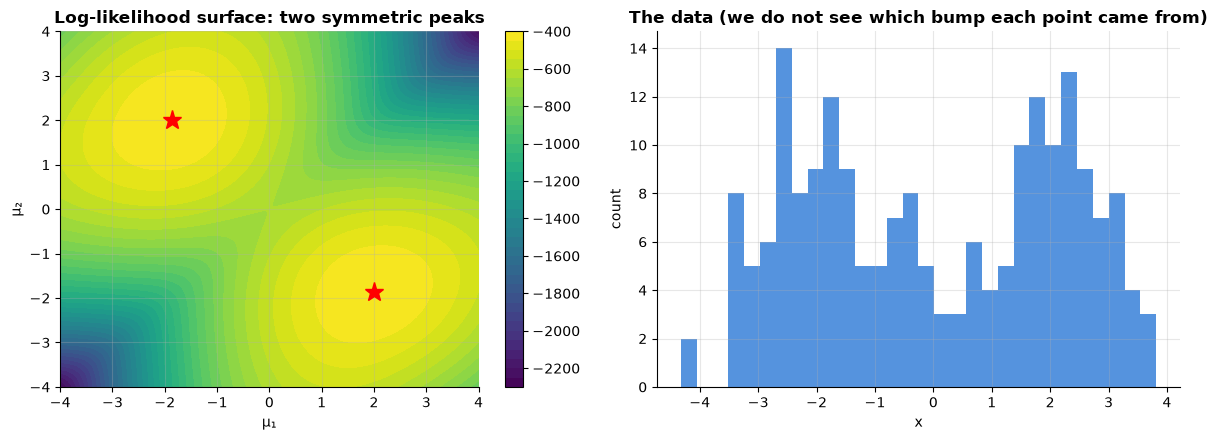

best grid point (mu1, mu2) = (np.float64(2.0), np.float64(-1.8666666666666667)) and its mirror image have equal log-lik: True


brute force over 2^8 assignments: 4.798987e-07   factorised: 4.798987e-07
number of joint assignments for N=1000, K=3: 3^1000 ≈ 10^477


In [2]:
# A 1-D mixture of two unit-variance Gaussians with equal weights
x1d = np.concatenate([rng.normal(-2, 1, 100), rng.normal(2, 1, 100)])

def mix_loglik(x, mu1, mu2):
    """log p(x | mu1, mu2) for the 50/50 mixture with sigma=1, summed over points."""
    comp = np.stack([stats.norm.logpdf(x, mu1, 1), stats.norm.logpdf(x, mu2, 1)])
    return logsumexp(comp + np.log(0.5), axis=0).sum()      # log of a SUM over z, per point

grid = np.linspace(-4, 4, 121)
LL = np.array([[mix_loglik(x1d, a, b) for a in grid] for b in grid])

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
cs = ax[0].contourf(grid, grid, LL, levels=40, cmap="viridis")
ax[0].set_xlabel("μ₁"); ax[0].set_ylabel("μ₂"); ax[0].set_title("Log-likelihood surface: two symmetric peaks")
fig.colorbar(cs, ax=ax[0])
ib = np.unravel_index(LL.argmax(), LL.shape)
ax[0].plot(grid[ib[1]], grid[ib[0]], "r*", ms=14); ax[0].plot(grid[ib[0]], grid[ib[1]], "r*", ms=14)
ax[1].hist(x1d, bins=30, color=PALETTE[0], alpha=0.8)
ax[1].set_title("The data (we do not see which bump each point came from)"); ax[1].set_xlabel("x"); ax[1].set_ylabel("count")
plt.tight_layout(); plt.show()
print("best grid point (mu1, mu2) =", (grid[ib[1]], grid[ib[0]]), "and its mirror image have equal log-lik:",
      np.isclose(LL[ib], LL[ib[::-1]]))

# The sum over all K^N assignments really equals the product of per-point sums (i.i.d. case), checked by brute force
xs = x1d[:8]
brute = sum(np.exp(sum(np.log(0.5) + stats.norm.logpdf(xs[n], [-2, 2][z[n]], 1) for n in range(8)))
            for z in product([0, 1], repeat=8))                    # 2^8 = 256 assignments
fact = np.prod([0.5 * stats.norm.pdf(v, -2, 1) + 0.5 * stats.norm.pdf(v, 2, 1) for v in xs])
print(f"brute force over 2^8 assignments: {brute:.6e}   factorised: {fact:.6e}")
assert np.isclose(brute, fact)
print("number of joint assignments for N=1000, K=3: 3^1000 ≈ 10^%d" % int(1000 * np.log10(3)))

**What just happened?** The likelihood surface over (μ₁, μ₂) has **two identical peaks**, one at roughly (−2, 2) and its mirror image (2, −2). This is **label switching**: the model does not care which bump we call "1". Any local optimiser will find one of them depending on where it starts. The brute-force sum over all 256 hidden assignments of 8 points matches the factorised formula, which shows the "sum over z" is the true definition of the likelihood. For i.i.d. mixtures it factorises per point, but for models with dependent latents (HMMs, Section 5) it does not, and we need dynamic programming.

> ⚠️ **Common mistake:** writing `log Σ_z p(x,z) = Σ_z log p(x,z)`. The log of a sum is **not** the sum of logs. That single fact is why EM, VI and MCMC exist.

## 2. EM derived: Jensen's inequality and the ELBO

> 💬 **In plain English:** build a simpler curve that sits under the real one and touches it, climb that curve, repeat.

**Intuition.** We cannot maximise `log Σ_z p(x,z)` directly, but we *can* build a simpler function that sits **below** it everywhere and **touches** it at the current parameters. Push that lower bound up, and the true likelihood must rise too. This is the "minorise–maximise" idea.

**Derivation.** Pick any distribution `q(z)` over the latents. Multiply and divide by it, then apply **Jensen's inequality** (`log E[Y] ≥ E[log Y]` because log is concave):

$$\log p(x\mid\theta) = \log \sum_z q(z)\,\frac{p(x,z\mid\theta)}{q(z)} \;\ge\; \sum_z q(z)\log\frac{p(x,z\mid\theta)}{q(z)} \;=:\; \mathcal{L}(q,\theta).$$

`𝓛(q, θ)` is the **evidence lower bound (ELBO)**. The gap is exactly a KL divergence:

$$\log p(x\mid\theta) = \mathcal{L}(q,\theta) + \mathrm{KL}\big(q(z)\,\|\,p(z\mid x,\theta)\big), \qquad \mathrm{KL}\ge 0.$$

**EM is coordinate ascent on the ELBO:**
- **E-step:** with θ fixed, maximise over q. The best q makes the KL zero: `q(z) = p(z | x, θ_old)`, the posterior ("responsibilities").
- **M-step:** with q fixed, maximise over θ. Since the entropy of q does not depend on θ, this is maximising the **expected complete-data log-likelihood** `Q(θ, θ_old) = E_{q}[log p(x, z | θ)]`, which usually has a closed form.

**Why the likelihood never decreases:** `log p(x|θ_new) ≥ 𝓛(q, θ_new) ≥ 𝓛(q, θ_old) = log p(x|θ_old)`. The first inequality is the bound, the second is the M-step, the equality is the E-step (KL = 0). EM converges to a stationary point (usually a local maximum), not necessarily the global one.

Let us check the identity `log p(x) = ELBO + KL` numerically for one data point and a 3-component mixture.

In [3]:
# One observation x, a 3-component 1-D mixture; the latent z has 3 possible values
pis_t, mus_t, sds_t = np.array([0.2, 0.5, 0.3]), np.array([-2.0, 0.0, 3.0]), np.array([1.0, 0.7, 1.5])
x0 = 1.2
log_joint = np.log(pis_t) + stats.norm.logpdf(x0, mus_t, sds_t)   # log p(x, z=k) for k=0,1,2
log_px = logsumexp(log_joint)                                     # log p(x): the evidence
post = np.exp(log_joint - log_px)                                 # p(z | x): the exact posterior

def elbo_single(q):
    return np.sum(q * (log_joint - np.log(q)))                    # E_q[log p(x,z)] + entropy(q)

def kl(q, p):
    return np.sum(q * (np.log(q) - np.log(p)))

rows = []
for name, q in [("uniform", np.ones(3) / 3), ("random", rng.dirichlet(np.ones(3))),
                ("all mass on z=0", np.array([0.98, 0.01, 0.01])), ("exact posterior", post)]:
    rows.append([name, np.round(q, 3), elbo_single(q), kl(q, post), elbo_single(q) + kl(q, post)])
    assert np.isclose(elbo_single(q) + kl(q, post), log_px)        # the identity holds for EVERY q
df = pd.DataFrame(rows, columns=["q(z)", "values", "ELBO", "KL(q || posterior)", "ELBO + KL"])
print(f"log p(x) = {log_px:.4f}")
df

log p(x) = -2.2550


,q(z),values,ELBO,KL(q || posterior),ELBO + KL
0,uniform,"[0.333, 0.333, 0.333]",-3.4419,1.1869,-2.255
1,random,"[0.189, 0.165, 0.647]",-3.0985,0.8435,-2.255
2,all mass on z=0,"[0.98, 0.01, 0.01]",-7.4432,5.1882,-2.255
3,exact posterior,"[0.005, 0.625, 0.37]",-2.2550,0.0000,-2.255


**What just happened?** For every choice of `q`, `ELBO + KL` equals `log p(x)` to machine precision, and the ELBO is largest (and equal to `log p(x)`) when `q` is the exact posterior. The E-step is therefore "set q to the posterior", which closes the gap completely. When the posterior is intractable, we restrict q to a simple family and the gap stays positive: that is **variational inference** (Section 8).

> 🎓 **Exam / interview tip:** be able to write the two lines "Jensen → ELBO" and "log p = ELBO + KL" from memory, then state E-step = posterior, M-step = maximise expected complete-data log-likelihood, and the monotonicity chain. This answers "derive EM" in under five minutes.

## 3. EM for a Gaussian mixture model, from scratch

> 💬 **In plain English:** guess soft group memberships, re-fit each group's centre and shape, repeat until stable.

**Model.** `p(x) = Σₖ πₖ N(x | μₖ, Σₖ)` with mixing weights πₖ ≥ 0, Σπₖ = 1.

**E-step** (responsibilities, the posterior over z for each point):
$$r_{nk} = \frac{\pi_k\,\mathcal N(x_n\mid\mu_k,\Sigma_k)}{\sum_j \pi_j\,\mathcal N(x_n\mid\mu_j,\Sigma_j)}$$

**M-step** (weighted versions of the usual estimates, with `Nₖ = Σₙ r_nk`):
$$\pi_k = \frac{N_k}{N},\qquad \mu_k = \frac{1}{N_k}\sum_n r_{nk}x_n,\qquad \Sigma_k = \frac{1}{N_k}\sum_n r_{nk}(x_n-\mu_k)(x_n-\mu_k)^\top$$

**Worked example by hand** (1-D, K = 2, σ = 1 fixed, π = ½, current means μ₁ = 0, μ₂ = 4):

| x | N(x\|0,1) ∝ e^{−x²/2} | N(x\|4,1) ∝ e^{−(x−4)²/2} | r₁ | r₂ |
|---|---|---|---|---|
| 1 | 0.607 | 0.011 | 0.982 | 0.018 |
| 3 | 0.011 | 0.607 | 0.018 | 0.982 |
| 2 | 0.135 | 0.135 | 0.5 | 0.5 |

New μ₁ = (0.982·1 + 0.018·3 + 0.5·2) / (0.982 + 0.018 + 0.5) = 2.036 / 1.5 ≈ 1.357, and by symmetry μ₂ ≈ 2.643. The point x = 2 is shared equally: this "soft" assignment is what separates EM from k-means.

We work in **log space** with `logsumexp` so that tiny densities do not underflow to 0, and use a Cholesky factorisation to get the log-determinant and Mahalanobis distance stably.

In [4]:
# Check the hand-worked table above
xh, m_old = np.array([1.0, 3.0, 2.0]), np.array([0.0, 4.0])
lj = -0.5 * (xh[:, None] - m_old) ** 2                       # log N up to a shared constant
r = np.exp(lj - logsumexp(lj, axis=1, keepdims=True))
print("responsibilities:\n", r.round(3))
print("new means:", ((r * xh[:, None]).sum(0) / r.sum(0)).round(3))

responsibilities:
 [[0.982 0.018]
 [0.018 0.982]
 [0.5   0.5  ]]
new means: [1.357 2.643]


In [5]:
def gmm_log_resp(X, pis, mus, covs):
    """Return per-point log-likelihood (N,) and responsibilities (N,K) for a full-covariance GMM."""
    N, D = X.shape
    K = len(pis)
    logp = np.empty((N, K))
    for k in range(K):
        L = np.linalg.cholesky(covs[k])                      # covs[k] = L L^T
        sol = np.linalg.solve(L, (X - mus[k]).T)            # L^{-1}(x - mu)
        maha = (sol ** 2).sum(0)                            # Mahalanobis distance squared
        logdet = 2 * np.log(np.diag(L)).sum()               # log |Sigma_k|
        logp[:, k] = np.log(pis[k]) - 0.5 * (D * np.log(2 * np.pi) + logdet + maha)
    ll = logsumexp(logp, axis=1)                            # log p(x_n): log of the sum over k
    return ll, np.exp(logp - ll[:, None])                   # responsibilities r_nk

def gmm_em(X, K, init_means, n_iter=500, tol=1e-8, reg=1e-6):
    """EM for a GMM. Returns params and the log-likelihood after every E-step."""
    N, D = X.shape
    mus = init_means.copy().astype(float)
    covs = np.array([np.cov(X.T) for _ in range(K)])        # start with the data covariance
    pis = np.full(K, 1 / K)
    hist = []
    for it in range(n_iter):
        ll, R = gmm_log_resp(X, pis, mus, covs)             # E-step
        hist.append(ll.sum())
        if it > 0 and hist[-1] - hist[-2] < tol:            # converged: no meaningful improvement
            break
        Nk = R.sum(0)                                       # M-step: effective counts
        pis = Nk / N
        mus = (R.T @ X) / Nk[:, None]
        for k in range(K):
            d = X - mus[k]
            covs[k] = (R[:, k, None] * d).T @ d / Nk[k] + reg * np.eye(D)   # reg keeps it invertible
    return pis, mus, covs, np.array(hist)

# Synthetic data: 3 clusters with different shapes
true_means = np.array([[0, 0], [5, 1], [2, 5]])
true_covs = [np.array([[1.0, 0.6], [0.6, 1.0]]), np.array([[0.6, -0.3], [-0.3, 1.2]]), np.array([[1.5, 0], [0, 0.4]])]
Xg = np.vstack([rng.multivariate_normal(m, c, n) for m, c, n in zip(true_means, true_covs, [250, 200, 150])])
init = Xg[rng.choice(len(Xg), 3, replace=False)]
pis_h, mus_h, covs_h, hist = gmm_em(Xg, 3, init)
print(f"EM stopped after {len(hist)} E-steps; final log-likelihood = {hist[-1]:.3f}")
assert np.all(np.diff(hist) >= -1e-9), "EM must never decrease the log-likelihood"
print("log-likelihood is monotone non-decreasing:", np.all(np.diff(hist) >= -1e-9))

EM stopped after 46 E-steps; final log-likelihood = -2190.337
log-likelihood is monotone non-decreasing: True


max |mean difference| vs sklearn: 2e-06
max |weight difference| vs sklearn: 0.0
log-likelihood ours = -2190.3373   sklearn = -2190.3373


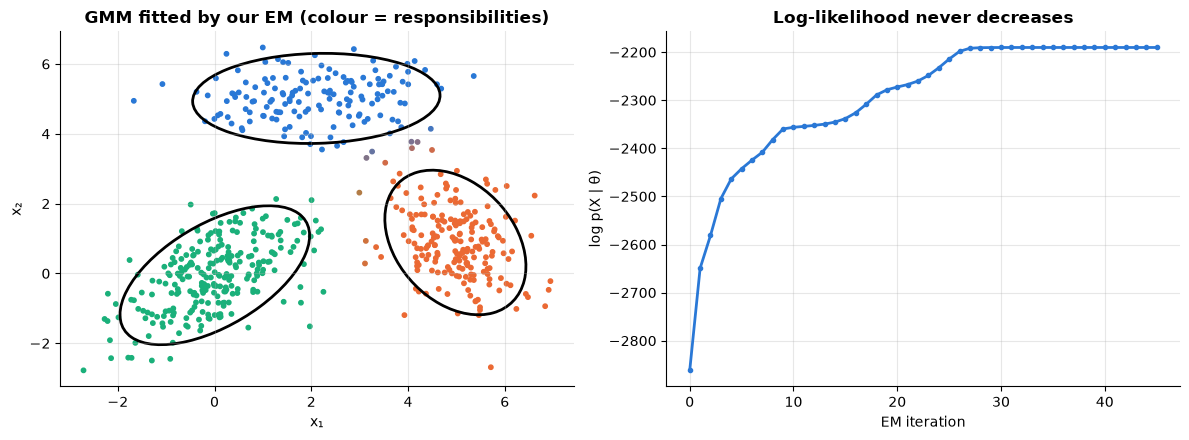

In [6]:
from sklearn.mixture import GaussianMixture

# Same initial means, same initial covariances and weights, so both should land on the same optimum
init_covs = np.array([np.cov(Xg.T)] * 3)
sk = GaussianMixture(3, covariance_type="full", means_init=init, weights_init=np.full(3, 1 / 3),
                     precisions_init=np.linalg.inv(init_covs), tol=1e-10, max_iter=1000, reg_covar=1e-6).fit(Xg)
order = [np.argmin(np.linalg.norm(sk.means_ - m, axis=1)) for m in mus_h]   # match components
print("max |mean difference| vs sklearn:", np.abs(sk.means_[order] - mus_h).max().round(6))
print("max |weight difference| vs sklearn:", np.abs(sk.weights_[order] - pis_h).max().round(6))
ll_ours = gmm_log_resp(Xg, pis_h, mus_h, covs_h)[0].sum()
print(f"log-likelihood ours = {ll_ours:.4f}   sklearn = {sk.score(Xg) * len(Xg):.4f}")
assert np.allclose(sk.means_[order], mus_h, atol=1e-3) and np.isclose(ll_ours, sk.score(Xg) * len(Xg), atol=1e-2)

def ellipse(ax, mean, cov, color):
    vals, vecs = np.linalg.eigh(cov)
    ang = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    ax.add_patch(Ellipse(mean, 2 * 2 * np.sqrt(vals[1]), 2 * 2 * np.sqrt(vals[0]), angle=ang,
                         fill=False, color=color, lw=2))         # 2-sigma ellipse

_, R = gmm_log_resp(Xg, pis_h, mus_h, covs_h)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(Xg[:, 0], Xg[:, 1], c=R @ np.array([[0.16, 0.47, 0.84], [0.92, 0.41, 0.2], [0.1, 0.69, 0.48]]), s=10)
for k in range(3):
    ellipse(ax[0], mus_h[k], covs_h[k], "k")
ax[0].set_title("GMM fitted by our EM (colour = responsibilities)"); ax[0].set_xlabel("x₁"); ax[0].set_ylabel("x₂")
ax[1].plot(hist, marker=".")
ax[1].set_title("Log-likelihood never decreases"); ax[1].set_xlabel("EM iteration"); ax[1].set_ylabel("log p(X | θ)")
plt.tight_layout(); plt.show()

In [7]:
# Local optima: on our 3 well-separated clusters every restart finds the same optimum,
# so use a harder problem: 8 blobs on a grid, K = 8, random initial means picked from the data
centres8 = np.array([[i, j] for i in range(4) for j in range(2)]) * 4.0
X8 = np.vstack([rng.normal(c, 0.6, size=(60, 2)) for c in centres8])
finals = []
for s in range(10):
    r_ = np.random.default_rng(100 + s)
    *_, h = gmm_em(X8, 8, X8[r_.choice(len(X8), 8, replace=False)], n_iter=300, tol=1e-6)
    finals.append(h[-1])
print("final log-likelihood per restart:", np.round(finals, 1))
print("best:", round(max(finals), 1), " worst:", round(min(finals), 1),
      " restarts within 1 of the best:", int(np.sum(np.array(finals) > max(finals) - 1)), "of 10")

final log-likelihood per restart: [-1916.4 -1864.1 -1864.1 -1913.2 -1907.5 -1924.8 -1864.1 -1864.1 -1916.8
 -1864.1]
best: -1864.1  worst: -1924.8  restarts within 1 of the best: 5 of 10


**What just happened?** Our EM and sklearn's `GaussianMixture`, started from the same point, agree on the means and weights to about 10⁻⁶. The log-likelihood curve rises quickly and then flattens, and never goes down (we assert this). On these three well-separated clusters any start works, but on the harder 8-blob problem different random starts end at different log-likelihoods: those are **local optima** (typically two components sharing one blob while one component straddles two blobs). Restarts that reach the same value are the same optimum, possibly with labels swapped. That is why sklearn has `n_init` and initialises with k-means by default.

**Complexity.** Each iteration costs **O(N·K·D²)** for the E-step and the covariance updates, plus **O(K·D³)** for the Cholesky factorisations. Memory is O(N·K) for the responsibilities. The number of iterations depends on how well separated the clusters are: EM converges *linearly*, and slowly when clusters overlap a lot.

> ⚠️ **Common mistake:** a component collapsing onto a single point (variance → 0, likelihood → ∞). This is a degenerate maximum of the GMM likelihood. The `reg * I` term (sklearn's `reg_covar`) or a prior on Σ (MAP-EM) prevents it.

> 🎓 **Exam / interview tip:** **k-means is "hard EM"** for a GMM with shared spherical covariance σ²I in the limit σ → 0: responsibilities become 0/1 (nearest centroid), and the M-step becomes "average of assigned points".

## 4. EM for missing data

> 💬 **In plain English:** treat each blank cell as a hidden value, fill it with its best guess plus its uncertainty, re-fit, repeat.

**Intuition.** A missing value is just another latent variable. EM fills it in with its *expected value given what we observed* (and, crucially, also accounts for the uncertainty of that guess), re-estimates the parameters, and repeats.

**Setting.** Pairs (x₁, x₂) ~ N(μ, Σ). Every x₁ is observed, but x₂ is missing for some rows. The data are **MAR (missing at random)**: whether x₂ is missing depends only on the observed x₁ (here: large x₁ → more likely missing). Under MAR, maximum likelihood on the observed data is valid, and EM computes it. Simply deleting incomplete rows ("complete-case analysis") is **biased** under MAR.

**E-step** for a row with missing x₂, using the conditional of a bivariate normal:
$$\mathbb E[x_2\mid x_1] = \mu_2 + \frac{\Sigma_{12}}{\Sigma_{11}}(x_1-\mu_1),\qquad \mathrm{Var}[x_2\mid x_1] = \Sigma_{22} - \frac{\Sigma_{12}^2}{\Sigma_{11}}$$
and we need the expected **sufficient statistics** `E[x₂]`, `E[x₂²] = Var + E[x₂]²` and `E[x₁x₂] = x₁E[x₂]`.

**M-step:** μ = average of the expected x, Σ = average of the expected xxᵀ minus μμᵀ.

In [8]:
mu_true = np.array([1.0, 2.0]); S_true = np.array([[1.0, 0.8], [0.8, 1.5]])
Xfull = rng.multivariate_normal(mu_true, S_true, 500)
p_miss = 1 / (1 + np.exp(-(2.5 * (Xfull[:, 0] - 1.0))))          # MAR: depends only on observed x1
miss = rng.random(500) < p_miss
Xobs = Xfull.copy(); Xobs[miss, 1] = np.nan
print(f"{miss.sum()} of 500 rows have x2 missing")

def obs_loglik(X, miss, mu, S):
    """Observed-data log-likelihood: full bivariate density for complete rows, x1-marginal for the rest."""
    full = stats.multivariate_normal(mu, S).logpdf(X[~miss]).sum()
    part = stats.norm(mu[0], np.sqrt(S[0, 0])).logpdf(X[miss, 0]).sum()
    return full + part

def em_missing(X, miss, n_iter=200, tol=1e-10):
    mu = np.nanmean(X, axis=0); S = np.diag(np.nanvar(X, axis=0))   # crude start
    hist = []
    for _ in range(n_iter):
        hist.append(obs_loglik(X, miss, mu, S))
        if len(hist) > 1 and hist[-1] - hist[-2] < tol:
            break
        # E-step: expected x2 and x2^2 for the missing rows
        Ex2 = X[:, 1].copy(); Ex2sq = X[:, 1] ** 2
        cm = mu[1] + S[0, 1] / S[0, 0] * (X[miss, 0] - mu[0])
        cv = S[1, 1] - S[0, 1] ** 2 / S[0, 0]
        Ex2[miss] = cm; Ex2sq[miss] = cv + cm ** 2                 # the "+ cv" is what naive imputation forgets
        # M-step
        mu = np.array([X[:, 0].mean(), Ex2.mean()])
        S11 = (X[:, 0] ** 2).mean() - mu[0] ** 2
        S12 = (X[:, 0] * Ex2).mean() - mu[0] * mu[1]
        S22 = Ex2sq.mean() - mu[1] ** 2
        S = np.array([[S11, S12], [S12, S22]])
    return mu, S, np.array(hist)

mu_em, S_em, h_m = em_missing(Xobs, miss)
assert np.all(np.diff(h_m) >= -1e-9)
cc = Xobs[~miss]                                                  # complete-case analysis
mean_imp = Xobs.copy(); mean_imp[miss, 1] = np.nanmean(Xobs[:, 1])  # mean imputation
res = pd.DataFrame({
    "true": [*mu_true, S_true[1, 1], S_true[0, 1]],
    "full-data MLE (no missingness)": [*Xfull.mean(0), Xfull[:, 1].var(), np.cov(Xfull.T, bias=True)[0, 1]],
    "complete cases only": [*cc.mean(0), cc[:, 1].var(), np.cov(cc.T, bias=True)[0, 1]],
    "mean imputation": [*mean_imp.mean(0), mean_imp[:, 1].var(), np.cov(mean_imp.T, bias=True)[0, 1]],
    "EM": [*mu_em, S_em[1, 1], S_em[0, 1]],
}, index=["mean x1", "mean x2", "var x2", "cov(x1,x2)"])
print(f"EM converged in {len(h_m)} iterations (observed-data log-lik is monotone)")
res.round(3)

254 of 500 rows have x2 missing
EM converged in 84 iterations (observed-data log-lik is monotone)


,true,full-data MLE (no missingness),complete cases only,mean imputation,EM
mean x1,1.0,1.024,0.363,1.024,1.024
mean x2,2.0,2.008,1.487,1.487,2.011
var x2,1.5,1.559,1.240,0.610,1.538
"cov(x1,x2)",0.8,0.738,0.355,0.175,0.730


**What just happened?** Because rows with large x₁ (and therefore, through the positive correlation, large x₂) were more likely to lose x₂, the **complete-case** mean of x₂ is too low, and it also distorts x₁'s mean because whole rows are dropped. **Mean imputation** keeps the mean of x₂ wrong and shrinks its variance and covariance (it pretends the filled-in values are certain). **EM** recovers estimates very close to the full-data MLE, which is the best any method could do with this sample.

> ⚠️ **Common mistake:** in the E-step, plugging in E[x₂] and squaring it. You must use `E[x₂²] = Var + E[x₂]²`. Forgetting the variance term makes EM converge to an underestimated Σ (this is exactly the "regression imputation" bias).

> 🎓 **Exam / interview tip:** know the three missingness mechanisms: **MCAR** (missing completely at random: deletion is unbiased, just wasteful), **MAR** (depends on observed data: likelihood methods like EM or multiple imputation are valid), **MNAR** (depends on the missing value itself: you need a model of the missingness).

## 5. EM for an HMM: the Baum–Welch algorithm

> 💬 **In plain English:** the same guess-and-refit idea for hidden states that change over time, like a casino secretly swapping dice.

**Intuition.** A hidden Markov model (HMM) has a hidden state that changes over time (a casino secretly swapping a fair die for a loaded one) and emits a visible symbol each step (the roll). The latent variables are no longer independent, so the sum over Kᵀ state paths does not factorise per time step. The **forward–backward** algorithm computes the needed posteriors in O(T·K²) by dynamic programming, and **Baum–Welch** is EM that uses them. HMM basics (and Viterbi) are in [`classical_ai/09`](../../00_AI_Fundamentals/classical_ai/09_uncertain_knowledge_and_reasoning.ipynb); here we focus on *learning* the parameters.

**Parameters:** initial distribution π, transition matrix `A[i, j] = P(z_{t+1}=j | z_t=i)`, emission matrix `B[i, o] = P(x_t=o | z_t=i)`.

- **E-step** (forward–backward, scaled to avoid underflow): `γ_t(i) = P(z_t = i | x)` and `ξ_t(i, j) = P(z_t = i, z_{t+1} = j | x)`.
- **M-step:** `π = γ₁`, `A[i,j] = Σ_t ξ_t(i,j) / Σ_t γ_t(i)`, `B[i,o] = Σ_{t: x_t=o} γ_t(i) / Σ_t γ_t(i)`. Expected counts replace observed counts.

In [9]:
def hmm_sample(pi, A, B, T, rng):
    z = np.empty(T, int); x = np.empty(T, int)
    z[0] = rng.choice(len(pi), p=pi)
    for t in range(T):
        if t > 0:
            z[t] = rng.choice(len(pi), p=A[z[t - 1]])
        x[t] = rng.choice(B.shape[1], p=B[z[t]])
    return z, x

def forward_backward(X, pi, A, B):
    """Scaled forward-backward for S independent sequences at once.
    X: int array (S, T). Returns total log p(X), gamma (S,T,K), xi summed over s and t (K,K)."""
    S, T = X.shape; K = len(pi)
    Bx = B[:, X].transpose(1, 2, 0)                          # (S, T, K): P(observed symbol | state)
    alpha = np.empty((S, T, K)); beta = np.empty((S, T, K)); c = np.empty((S, T))
    a = pi * Bx[:, 0]
    c[:, 0] = a.sum(1); alpha[:, 0] = a / c[:, :1]
    for t in range(1, T):                                    # forward: alpha_t ∝ P(z_t, x_1..t)
        a = (alpha[:, t - 1] @ A) * Bx[:, t]
        c[:, t] = a.sum(1); alpha[:, t] = a / c[:, t:t + 1]  # c_t = P(x_t | x_1..t-1): the scaling factor
    beta[:, -1] = 1.0
    for t in range(T - 2, -1, -1):                           # backward pass
        beta[:, t] = ((Bx[:, t + 1] * beta[:, t + 1]) @ A.T) / c[:, t + 1:t + 2]
    gamma = alpha * beta                                     # P(z_t | x); each row sums to 1
    # xi(i,j) = sum_{s,t} alpha_t(i) A(i,j) B(j, x_t+1) beta_t+1(j) / c_t+1   (vectorised over s and t)
    xi = np.einsum("sti,stj->ij", alpha[:, :-1], Bx[:, 1:] * beta[:, 1:] / c[:, 1:, None]) * A
    return np.log(c).sum(), gamma, xi

def baum_welch(X, K, M, rng, n_iter=300, tol=1e-4):
    pi = np.full(K, 1 / K)
    A = rng.dirichlet(np.ones(K) * 5, size=K)                # random starting point
    B = rng.dirichlet(np.ones(M) * 5, size=K)
    hist = []
    for _ in range(n_iter):
        ll, gamma, xi = forward_backward(X, pi, A, B)        # E-step
        hist.append(ll)
        if len(hist) > 1 and hist[-1] - hist[-2] < tol:
            break
        pi = gamma[:, 0].mean(0)                              # M-step: expected counts, normalised
        A = xi / xi.sum(1, keepdims=True)
        B = np.stack([gamma[X == o].sum(0) for o in range(M)], axis=1)
        B /= B.sum(1, keepdims=True)
    return pi, A, B, np.array(hist)

# "Occasionally dishonest casino": state 0 = fair die, state 1 = loaded die (six comes up half the time)
pi0 = np.array([0.5, 0.5])
A0 = np.array([[0.95, 0.05], [0.10, 0.90]])
B0 = np.array([[1 / 6] * 6, [0.1] * 5 + [0.5]])

# 1) Check the forward algorithm against brute force over all 2^6 hidden paths
zs, xs6 = hmm_sample(pi0, A0, B0, 6, rng)
brute = logsumexp([np.log(pi0[p[0]]) + sum(np.log(A0[p[t - 1], p[t]]) for t in range(1, 6))
                   + sum(np.log(B0[p[t], xs6[t]]) for t in range(6)) for p in product([0, 1], repeat=6)])
fwd = forward_backward(xs6[None, :], pi0, A0, B0)[0]
print(f"log p(x) forward = {fwd:.6f}, brute force = {brute:.6f}")
assert np.isclose(fwd, brute)

# 2) Learn the parameters from 40 evenings x 100 rolls = 4000 rolls, without seeing the states
sims = [hmm_sample(pi0, A0, B0, 100, rng) for _ in range(40)]
Z_true = np.array([z for z, _ in sims]); ROLLS = np.array([x for _, x in sims])
t0 = time.time()
pi_h, A_h, B_h, h_hmm = baum_welch(ROLLS, 2, 6, np.random.default_rng(3))
assert np.all(np.diff(h_hmm) >= -1e-6)
perm = np.argsort(B_h[:, 5])                                 # align: loaded state = higher P(six)
A_h, B_h, pi_h = A_h[perm][:, perm], B_h[perm], pi_h[perm]
print(f"Baum-Welch: {len(h_hmm)} iterations in {time.time() - t0:.1f}s, log-lik monotone")
print("learned A:\n", A_h.round(3), "\ntrue A:\n", A0)
print("learned B:\n", B_h.round(3))

log p(x) forward = -9.394952, brute force = -9.394952


Baum-Welch: 194 iterations in 1.2s, log-lik monotone
learned A:
 [[0.954 0.046]
 [0.097 0.903]] 
true A:
 [[0.95 0.05]
 [0.1  0.9 ]]
learned B:
 [[0.164 0.164 0.171 0.17  0.178 0.153]
 [0.105 0.084 0.12  0.098 0.079 0.513]]


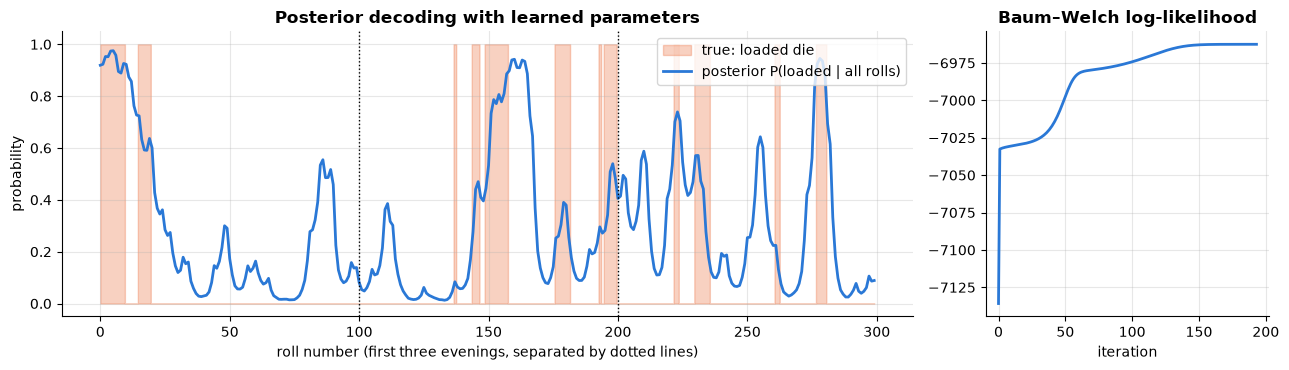

state accuracy of posterior decoding: 0.820


In [10]:
_, gam, _ = forward_backward(ROLLS, pi_h, A_h, B_h)
acc = ((gam[..., 1] > 0.5) == (Z_true == 1)).mean()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [3, 1]})
ax[0].fill_between(range(300), Z_true[:3].ravel(), step="mid", alpha=0.3, color=PALETTE[1], label="true: loaded die")
ax[0].plot(gam[:3, :, 1].ravel(), color=PALETTE[0], label="posterior P(loaded | all rolls)")
for b in (100, 200):
    ax[0].axvline(b, color="k", lw=1, ls=":")
ax[0].set_xlabel("roll number (first three evenings, separated by dotted lines)"); ax[0].set_ylabel("probability")
ax[0].set_title("Posterior decoding with learned parameters"); ax[0].legend(loc="upper right")
ax[1].plot(h_hmm); ax[1].set_title("Baum–Welch log-likelihood"); ax[1].set_xlabel("iteration")
plt.tight_layout(); plt.show()
print(f"state accuracy of posterior decoding: {acc:.3f}")

**What just happened?** First we checked that the forward algorithm's log p(x) equals a brute-force sum over all 64 hidden paths. Then Baum–Welch learned the casino's transition and emission probabilities from 40 independent sequences of rolls alone (the E-step simply sums expected counts over sequences, and we vectorise across them). The learned matrices are close to the truth (a few hundredths off, which is ordinary sampling error for 4000 rolls), and the posterior P(loaded) tracks the true hidden state well.

**Complexity.** Forward–backward is **O(T·K²)** time and O(T·K) memory per sequence per EM iteration, versus O(Kᵀ) for brute force.

> ⚠️ **Common mistake:** running forward–backward without scaling (or without log space). For long sequences the unscaled α values underflow to exactly 0 after a few hundred steps.

## 6. Gibbs sampling

> 💬 **In plain English:** update one unknown at a time, drawing it at random given all the others; over time the draws follow the true probabilities.

**Intuition.** Sampling from a joint distribution over many variables is hard, but sampling **one variable given all the others** is often easy. Gibbs sampling repeatedly picks each variable in turn and redraws it from its **full conditional** `p(x_i | x_{−i})`. The sequence of states forms a Markov chain whose stationary distribution is the target. Gibbs is a special case of Metropolis–Hastings ([`14/07`](../../14_Mathematics/07_bayesian_ml.ipynb)) where every proposal is accepted (acceptance probability exactly 1).

**Definition (systematic-scan Gibbs).** For t = 1, 2, …: for i = 1..d, draw `x_i^{(t)} ~ p(x_i | x_1^{(t)}, …, x_{i−1}^{(t)}, x_{i+1}^{(t−1)}, …, x_d^{(t−1)})`.

### 6.1 A bivariate normal
For a standard bivariate normal with correlation ρ, the full conditionals are `x₁ | x₂ ~ N(ρx₂, 1 − ρ²)` and `x₂ | x₁ ~ N(ρx₁, 1 − ρ²)`.

rho=0.5: sample means [ 0.005 -0.003], sample corr 0.493
rho=0.99: sample means [0.028 0.029], sample corr 0.990


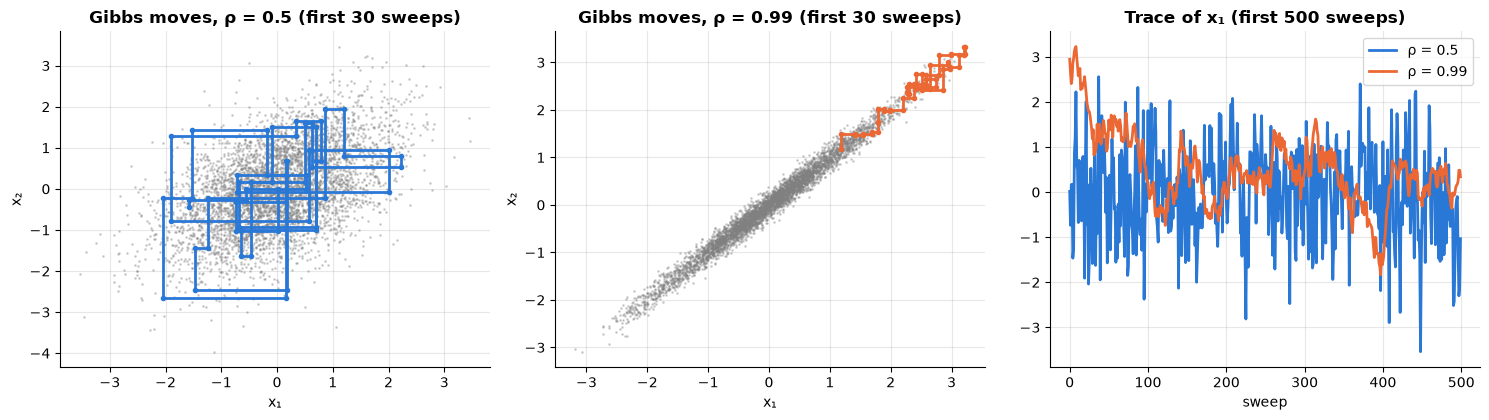

In [11]:
def gibbs_bvn(rho, n, x_init=(0.0, 0.0), rng=rng):
    """Systematic-scan Gibbs for a standard bivariate normal with correlation rho."""
    out = np.empty((n, 2)); a, b = x_init; sd = np.sqrt(1 - rho ** 2)
    for t in range(n):
        a = rng.normal(rho * b, sd)                      # draw x1 | x2
        b = rng.normal(rho * a, sd)                      # draw x2 | x1 (uses the NEW x1)
        out[t] = a, b
    return out

fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for j, rho in enumerate([0.5, 0.99]):
    s = gibbs_bvn(rho, 5000, x_init=(-3, 3) if rho > 0.9 else (0, 0))
    print(f"rho={rho}: sample means {s.mean(0).round(3)}, sample corr {np.corrcoef(s.T)[0, 1]:.3f}")
    pts, prev_b = [], (3 if rho > 0.9 else 0)
    for a_, b_ in s[:30]:                                   # each sweep = horizontal move, then vertical move
        pts += [(a_, prev_b), (a_, b_)]; prev_b = b_
    path = np.array(pts)
    ax[j].plot(*s[:, :].T, ".", ms=2, alpha=0.3, color="grey")
    ax[j].plot(path[:, 0], path[:, 1], "-o", ms=3, color=PALETTE[j])
    ax[j].set_title(f"Gibbs moves, ρ = {rho} (first 30 sweeps)"); ax[j].set_xlabel("x₁"); ax[j].set_ylabel("x₂")
    ax[2].plot(s[:500, 0], label=f"ρ = {rho}", color=PALETTE[j])
ax[2].set_title("Trace of x₁ (first 500 sweeps)"); ax[2].set_xlabel("sweep"); ax[2].legend()
plt.tight_layout(); plt.show()

**What just happened?** Gibbs moves only parallel to the axes (the "staircase"). When ρ = 0.5 that is fine and the chain explores freely. When ρ = 0.99 the target is a thin diagonal ridge, each axis-parallel step is tiny, and the trace wanders slowly: consecutive samples are highly correlated. The chain is still correct in the long run, but each sample carries little new information. Section 7 measures this with the effective sample size.

### 6.2 Gibbs for a Bayesian Gaussian mixture
**Model** (1-D, K components, known σ = 1): `π ~ Dirichlet(α)`, `μₖ ~ N(0, τ₀²)`, `zₙ ~ Cat(π)`, `xₙ ~ N(μ_{zₙ}, 1)`. All full conditionals are conjugate:

| Variable | Full conditional |
|---|---|
| zₙ | `P(zₙ = k | …) ∝ πₖ · N(xₙ | μₖ, 1)` |
| π | `Dirichlet(α + n₁, …, α + n_K)`, where nₖ = #points with z = k |
| μₖ | `N(m, v)` with `v = 1/(1/τ₀² + nₖ)`, `m = v · Σ_{n: zₙ=k} xₙ` |

2000 Gibbs sweeps in 1.7s


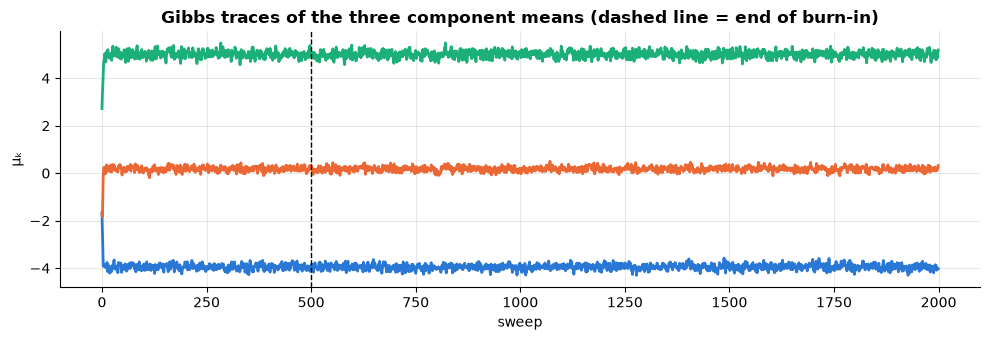

,true μ,posterior mean μ,posterior sd μ,true π,posterior mean π
0,-4.0,-3.950,0.113,0.3,0.330
1,0.0,0.176,0.097,0.5,0.471
2,5.0,5.004,0.139,0.2,0.199


In [12]:
# Data for the Bayesian GMM (also reused by VI in Section 8)
true_mu_b, true_w_b = np.array([-4.0, 0.0, 5.0]), np.array([0.3, 0.5, 0.2])
zb = rng.choice(3, 300, p=true_w_b)
xb = rng.normal(true_mu_b[zb], 1.0)

def gibbs_bgmm(x, K=3, n_iter=2000, alpha=1.0, tau0=10.0, seed=1):
    r = np.random.default_rng(seed)
    N = len(x)
    mu = r.normal(0, 1, K); pi = np.full(K, 1 / K)
    trace_mu = np.empty((n_iter, K)); trace_pi = np.empty((n_iter, K))
    for it in range(n_iter):
        logp = np.log(pi) - 0.5 * (x[:, None] - mu) ** 2             # (N, K) unnormalised log P(z_n = k)
        p = np.exp(logp - logsumexp(logp, axis=1, keepdims=True))
        z = (r.random(N)[:, None] > p.cumsum(1)).sum(1)              # vectorised categorical draws
        z = np.minimum(z, K - 1)
        nk = np.bincount(z, minlength=K)
        pi = r.dirichlet(alpha + nk)                                 # draw pi | z
        v = 1 / (1 / tau0 ** 2 + nk)                                 # draw each mu_k | z, x
        m = v * np.bincount(z, weights=x, minlength=K)
        mu = r.normal(m, np.sqrt(v))
        order = np.argsort(mu)                                       # relabel to undo label switching
        trace_mu[it], trace_pi[it] = mu[order], pi[order]
    return trace_mu, trace_pi

t0 = time.time()
tr_mu, tr_pi = gibbs_bgmm(xb)
burn = 500
print(f"{len(tr_mu)} Gibbs sweeps in {time.time() - t0:.1f}s")
summary = pd.DataFrame({"true μ": true_mu_b, "posterior mean μ": tr_mu[burn:].mean(0),
                        "posterior sd μ": tr_mu[burn:].std(0), "true π": true_w_b,
                        "posterior mean π": tr_pi[burn:].mean(0)})
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(tr_mu); ax.axvline(burn, ls="--", color="k", lw=1)
ax.set_title("Gibbs traces of the three component means (dashed line = end of burn-in)")
ax.set_xlabel("sweep"); ax.set_ylabel("μₖ"); plt.tight_layout(); plt.show()
summary.round(3)

**What just happened?** After a short burn-in, the three mean traces settle around −4, 0 and 5 and jiggle with a spread of roughly `1/√nₖ`, which is the posterior uncertainty. Unlike EM, which gives one best estimate, Gibbs gives a **distribution** over the parameters. We sorted the means each sweep to remove **label switching**; this is a simple fix that works when the components are well separated.

### 6.3 Collapsed Gibbs for LDA on a toy corpus
**Latent Dirichlet Allocation (LDA)** is a mixture model for documents: each document has topic proportions θ_d ~ Dir(α), each topic has a word distribution φ_k ~ Dir(β), each word picks a topic z ~ Cat(θ_d) and then a word w ~ Cat(φ_z). **Collapsed** Gibbs integrates out θ and φ analytically (Dirichlet–multinomial conjugacy) and samples only the word-level topic assignments (Griffiths & Steyvers, 2004):

$$P(z_i = k \mid z_{-i}, w) \;\propto\; (n_{dk}^{-i} + \alpha)\;\frac{n_{kw}^{-i} + \beta}{n_{k}^{-i} + V\beta}$$

where the counts exclude the current word i. "How much does this document like topic k" × "how much does topic k like this word". The applied version with sklearn is in [`07_NLP/07_topic_modeling`](../../07_NLP/07_topic_modeling.ipynb).

In [13]:
# A toy corpus with three planted topics
topics_true = {
    "sports": ["ball", "goal", "team", "coach", "score", "match", "league"],
    "food":   ["pizza", "pasta", "chef", "recipe", "oven", "sauce", "spicy"],
    "tech":   ["code", "python", "laptop", "server", "bug", "cloud", "data"],
}
vocab = [w for ws in topics_true.values() for w in ws]
V, Kt = len(vocab), 3
w2i = {w: i for i, w in enumerate(vocab)}
rc = np.random.default_rng(7)
docs = []
for d in range(40):
    theta = rc.dirichlet([0.3] * Kt)                     # each document mixes a few topics
    words = []
    for _ in range(20):
        k = rc.choice(Kt, p=theta)
        words.append(w2i[rc.choice(list(topics_true.values())[k])])
    docs.append(np.array(words))
print("example document:", " ".join(vocab[i] for i in docs[0][:15]), "...")

def lda_collapsed_gibbs(docs, K, V, alpha=0.5, beta=0.1, n_sweeps=100, seed=0):
    r = np.random.default_rng(seed)
    z = [r.integers(K, size=len(d)) for d in docs]       # random initial topic for every token
    ndk = np.zeros((len(docs), K)); nkw = np.zeros((K, V)); nk = np.zeros(K)
    for d, (doc, zd) in enumerate(zip(docs, z)):
        for w, k in zip(doc, zd):
            ndk[d, k] += 1; nkw[k, w] += 1; nk[k] += 1
    for sweep in range(n_sweeps):
        for d, doc in enumerate(docs):
            u = r.random(len(doc))                                 # one uniform number per token
            for i, w in enumerate(doc):
                k = z[d][i]
                ndk[d, k] -= 1; nkw[k, w] -= 1; nk[k] -= 1          # remove token i from the counts
                p = (ndk[d] + alpha) * (nkw[:, w] + beta) / (nk + V * beta)
                cp = np.cumsum(p)
                k = int(np.searchsorted(cp, u[i] * cp[-1]))        # resample its topic (inverse-CDF draw)
                z[d][i] = k
                ndk[d, k] += 1; nkw[k, w] += 1; nk[k] += 1          # add it back
    phi = (nkw + beta) / (nk[:, None] + V * beta)                 # posterior-mean topic-word matrix
    return phi, ndk

t0 = time.time()
phi, ndk = lda_collapsed_gibbs(docs, Kt, V)
print(f"collapsed Gibbs: 100 sweeps over {sum(map(len, docs))} tokens in {time.time() - t0:.1f}s")
for k in range(Kt):
    top = [vocab[i] for i in np.argsort(-phi[k])[:7]]
    print(f"topic {k}: {' '.join(top)}")
# Check each learned topic's top-7 words come from a single planted topic
purity = np.mean([max(len(set(vocab[i] for i in np.argsort(-phi[k])[:7]) & set(ws)) for ws in topics_true.values()) / 7
                  for k in range(Kt)])
print("average top-word purity vs planted topics:", round(purity, 3))

example document: coach sauce sauce team league recipe recipe spicy chef league league score ball recipe sauce ...


collapsed Gibbs: 100 sweeps over 800 tokens in 1.5s
topic 0: recipe oven chef sauce pasta pizza spicy
topic 1: goal team ball coach match league score
topic 2: cloud python server code bug data laptop
average top-word purity vs planted topics: 1.0


**What just happened?** Starting from random topic labels, the sampler sorted the 800 tokens into three topics whose top words are exactly the planted sports, food and tech vocabularies (purity 1.0, up to the order of topics, which is arbitrary). Collapsing θ and φ away leaves fewer variables to sample, which usually mixes much faster than sampling them explicitly.

**Complexity.** One Gibbs sweep of LDA costs **O(N_tokens · K)**. Bayesian-GMM Gibbs costs O(N·K) per sweep. Gibbs needs no step size and no tuning, but it requires conditionals you can sample, and it mixes slowly when variables are strongly correlated (Section 6.1).

## 7. MCMC diagnostics: trace plots, autocorrelation, ESS and R̂

> 💬 **In plain English:** check whether your random samples have settled down and how many 'truly independent' samples they are worth.

**Intuition.** MCMC samples are **correlated**, so 5000 samples are worth less than 5000 independent draws. We also never know for sure that a chain has reached its stationary distribution. Diagnostics cannot prove convergence, but they reliably catch the common failures.

**Definitions.**
- **Autocorrelation at lag k:** `ρ_k = Corr(x_t, x_{t+k})`.
- **Effective sample size:** `ESS = N / (1 + 2 Σ_{k≥1} ρ_k)`. The variance of the chain's mean is about `Var(x)/ESS`. We truncate the sum with **Geyer's initial positive sequence**: add autocorrelations in pairs `ρ_{2m} + ρ_{2m+1}` until a pair becomes negative.
- **Split-R̂ (Gelman–Rubin):** run M chains from spread-out starts, split each in half, and compare between-chain variance B with within-chain variance W: `R̂ = sqrt(((n−1)/n · W + B/n) / W)`. Values near 1 suggest the chains agree. A common modern rule is R̂ < 1.01 (Vehtari et al., 2021).

**A check we can do exactly.** For the Gibbs sampler of Section 6.1, the x₁-chain is an **AR(1) process** with coefficient φ = ρ² (substitute one conditional into the other). For AR(1), `ρ_k = φ^k`, so `ESS/N = (1 − φ)/(1 + φ)`. Our numpy ESS should reproduce this.

In [14]:
def autocorr(x, max_lag=None):
    """Autocorrelation function via FFT (O(N log N))."""
    x = np.asarray(x, float) - np.mean(x)
    n = len(x)
    f = np.fft.rfft(x, n=2 * n)                                   # zero-pad to avoid circular wrap
    acf = np.fft.irfft(f * np.conj(f))[:n]
    acf /= acf[0]
    return acf if max_lag is None else acf[:max_lag + 1]

def ess(x):
    """Effective sample size with Geyer's initial positive sequence truncation."""
    rho = autocorr(x)
    n = len(x)
    s = 0.0
    for m in range(0, n // 2 - 1):
        pair = rho[2 * m] + rho[2 * m + 1]                        # Gamma_m = rho_2m + rho_2m+1
        if pair < 0:
            break
        s += pair
    tau = -1 + 2 * s                                              # integrated autocorrelation time
    return n / tau

def split_rhat(chains):
    """chains: array (M, n). Split each chain in half, then Gelman-Rubin R-hat."""
    chains = np.asarray(chains)
    half = chains.shape[1] // 2
    c = np.vstack([chains[:, :half], chains[:, half:2 * half]])   # 2M chains of length half
    n = c.shape[1]
    W = c.var(axis=1, ddof=1).mean()                              # within-chain variance
    B = n * c.mean(axis=1).var(ddof=1)                            # between-chain variance
    var_plus = (n - 1) / n * W + B / n
    return np.sqrt(var_plus / W)

rows = []
for rho in [0.5, 0.9, 0.99]:
    chain = gibbs_bvn(rho, 20000, rng=np.random.default_rng(11))[:, 0]
    phi_ = rho ** 2
    rows.append([rho, phi_, ess(chain) / len(chain), (1 - phi_) / (1 + phi_)])
diag = pd.DataFrame(rows, columns=["ρ", "AR(1) φ = ρ²", "ESS/N (numpy estimate)", "ESS/N (theory)"])
for _, r_ in diag.iterrows():
    assert abs(r_.iloc[2] - r_.iloc[3]) / r_.iloc[3] < 0.25, "ESS estimate should be near theory"
diag.round(4)

,ρ,AR(1) φ = ρ²,ESS/N (numpy estimate),ESS/N (theory)
0,0.50,0.2500,0.6088,0.600
1,0.90,0.8100,0.1136,0.105
2,0.99,0.9801,0.0084,0.010


rho=0.5: split R-hat = 1.004
rho=0.99: split R-hat = 1.319


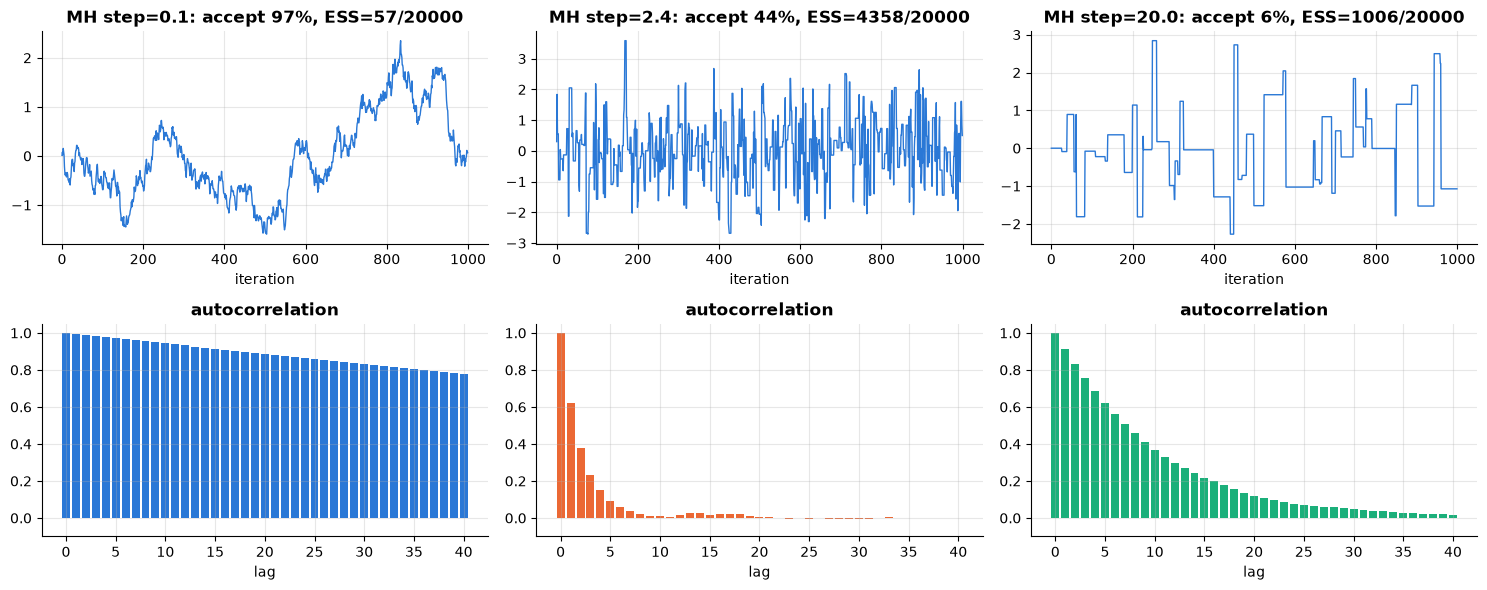

In [15]:
# R-hat: 4 chains from over-dispersed starting points, 400 sweeps each
for rho in [0.5, 0.99]:
    starts = [(-6, 6), (6, -6), (-6, -6), (6, 6)]
    chains = np.array([gibbs_bvn(rho, 400, x_init=s_, rng=np.random.default_rng(20 + i))[:, 0]
                       for i, s_ in enumerate(starts)])
    print(f"rho={rho}: split R-hat = {split_rhat(chains):.3f}")

# Random-walk Metropolis on N(0,1) with three step sizes (compare 14_Mathematics/07)
def rw_metropolis(step, n=20000, seed=0):
    r = np.random.default_rng(seed); x = 0.0; out = np.empty(n); acc = 0
    for t in range(n):
        prop = x + step * r.normal()
        if np.log(r.random()) < -0.5 * (prop ** 2 - x ** 2):    # log acceptance ratio for N(0,1)
            x = prop; acc += 1
        out[t] = x
    return out, acc / n

fig, ax = plt.subplots(2, 3, figsize=(15, 6))
for j, step in enumerate([0.1, 2.4, 20.0]):
    ch, ar = rw_metropolis(step)
    ax[0, j].plot(ch[:1000], lw=1); ax[0, j].set_title(f"MH step={step}: accept {ar:.0%}, ESS={ess(ch):.0f}/20000")
    ax[0, j].set_xlabel("iteration")
    ax[1, j].bar(range(41), autocorr(ch, 40), color=PALETTE[j]); ax[1, j].set_title("autocorrelation")
    ax[1, j].set_xlabel("lag"); ax[1, j].set_ylim(-0.1, 1.05)
plt.tight_layout(); plt.show()

**What just happened?**
- Our ESS estimate matches the AR(1) theory `(1 − φ)/(1 + φ)` for all three correlations (asserted within 25%). At ρ = 0.99, 20 000 Gibbs sweeps are worth only about 170 (our estimate) to 200 (theory) independent draws.
- Split-R̂ is about 1.00 for the well-mixing chain (ρ = 0.5) but clearly above 1.01 for ρ = 0.99: the four chains have not yet forgotten their starting points after 400 sweeps.
- For random-walk Metropolis, a tiny step accepts almost everything but crawls (high autocorrelation, low ESS). A huge step is rejected almost always (the chain gets stuck: flat segments in the trace). A step near **2.4σ** (the classic optimal scaling for one dimension, acceptance ≈ 44%) gives the highest ESS.

> ⚠️ **Common mistake:** judging a sampler by its acceptance rate or by the raw number of samples. Report **ESS** (or ESS per second) and **R̂** from several chains instead.

> 🎓 **Exam / interview tip:** "Why discard burn-in? Why thin?" Burn-in removes samples taken before the chain reached the typical set. Thinning (keeping every k-th sample) does **not** add information; it only saves memory. For a fixed amount of computation, the un-thinned chain always has at least as large an ESS.

## 8. Mean-field variational inference (CAVI)

> 💬 **In plain English:** replace the true, complicated answer with the closest simple shape, found by climbing the ELBO.

**Intuition.** Instead of sampling from the posterior, *choose* the best approximation from a simple family by optimisation. "Best" means closest in **KL(q ‖ p)**, which is the same as **maximising the ELBO** (Section 2). With the **mean-field** family, q factorises over groups of variables: `q(θ) = Πⱼ qⱼ(θⱼ)`.

**CAVI (coordinate ascent VI).** Holding all other factors fixed, the optimal factor is
$$\log q_j^*(\theta_j) = \mathbb{E}_{q_{-j}}\big[\log p(x, \theta)\big] + \text{const}.$$
For conjugate-exponential models each update has a closed form, and each one cannot decrease the ELBO, so the ELBO curve is monotone (a good debugging check, just like EM's likelihood).

### 8.1 A Gaussian with unknown mean and precision (Bishop PRML §10.1.3)
Model: `x_n ~ N(μ, τ⁻¹)`, prior `μ | τ ~ N(μ₀, (λ₀τ)⁻¹)`, `τ ~ Gamma(a₀, b₀)`. The exact posterior is Normal-Gamma (μ and τ are **dependent**). Mean-field assumes `q(μ, τ) = q(μ) q(τ)`:

| Factor | Update |
|---|---|
| q(μ) = N(μ_N, λ_N⁻¹) | `μ_N = (λ₀μ₀ + N x̄)/(λ₀ + N)`, `λ_N = (λ₀ + N) E[τ]` |
| q(τ) = Gamma(a_N, b_N) | `a_N = a₀ + (N+1)/2`, `b_N = b₀ + ½ E_μ[Σₙ(xₙ − μ)² + λ₀(μ − μ₀)²]` |

Because this model also has a closed-form exact posterior and evidence, we can check that the ELBO stays **below** log p(x) and see what mean-field misses.

final ELBO = -17.7000  <=  exact log evidence = -17.6647  (gap = KL = 0.0353)
        exact  mean-field VI
E[μ]   1.3006         1.3006
sd[μ]  0.2656         0.2459
E[τ]   1.2725         1.2725


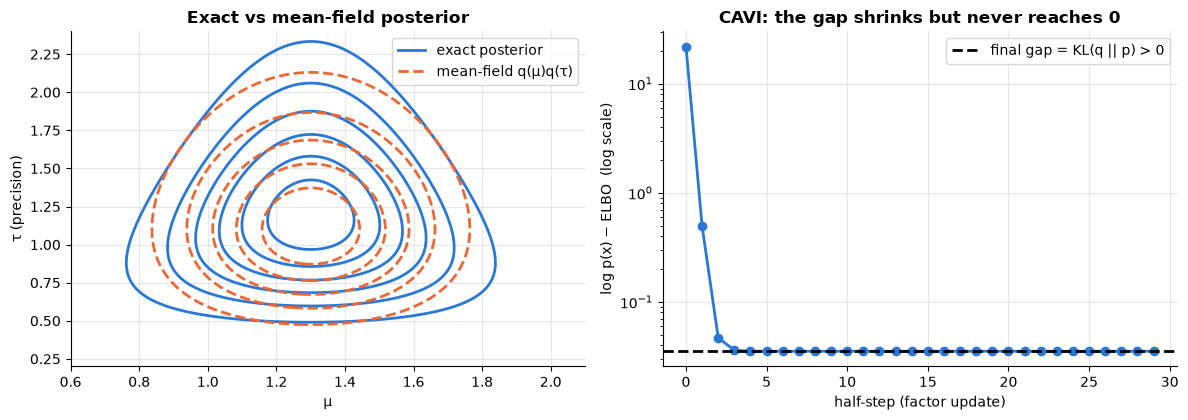

In [16]:
xg = rng.normal(1.5, 0.8, 12)                         # small N so the posterior is broad
N_, xbar = len(xg), xg.mean()
mu0, lam0, a0, b0 = 0.0, 1.0, 1.0, 1.0

# Exact Normal-Gamma posterior and log evidence
lamN_ex = lam0 + N_; muN_ex = (lam0 * mu0 + N_ * xbar) / lamN_ex
aN_ex = a0 + N_ / 2
bN_ex = b0 + 0.5 * ((xg - xbar) ** 2).sum() + lam0 * N_ * (xbar - mu0) ** 2 / (2 * lamN_ex)
log_evidence = (gammaln(aN_ex) - gammaln(a0) + a0 * np.log(b0) - aN_ex * np.log(bN_ex)
                + 0.5 * np.log(lam0 / lamN_ex) - N_ / 2 * np.log(2 * np.pi))

def elbo_ng(muN, lamN, aN, bN):
    Etau, Elogtau = aN / bN, digamma(aN) - np.log(bN)
    Esq = ((xg - muN) ** 2).sum() + N_ / lamN                      # E_q[Σ (x_n - μ)^2]
    Emu0 = (muN - mu0) ** 2 + 1 / lamN                             # E_q[(μ - μ0)^2]
    lik = N_ / 2 * Elogtau - N_ / 2 * np.log(2 * np.pi) - Etau / 2 * Esq
    pmu = 0.5 * np.log(lam0) + 0.5 * Elogtau - 0.5 * np.log(2 * np.pi) - lam0 * Etau / 2 * Emu0
    ptau = a0 * np.log(b0) - gammaln(a0) + (a0 - 1) * Elogtau - b0 * Etau
    Hmu = 0.5 * np.log(2 * np.pi * np.e / lamN)                    # entropy of q(μ)
    Htau = aN - np.log(bN) + gammaln(aN) + (1 - aN) * digamma(aN)  # entropy of q(τ)
    return lik + pmu + ptau + Hmu + Htau

aN, bN = a0 + (N_ + 1) / 2, 1.0                                    # a_N never changes; arbitrary start for b_N
muN = (lam0 * mu0 + N_ * xbar) / (lam0 + N_)                       # μ_N never changes either
elbos = []
for it in range(15):
    lamN = (lam0 + N_) * aN / bN                                   # update q(μ)
    elbos.append(elbo_ng(muN, lamN, aN, bN))
    bN = b0 + 0.5 * (((xg - muN) ** 2).sum() + N_ / lamN + lam0 * ((muN - mu0) ** 2 + 1 / lamN))  # update q(τ)
    elbos.append(elbo_ng(muN, lamN, aN, bN))
assert np.all(np.diff(elbos) >= -1e-10) and elbos[-1] <= log_evidence
print(f"final ELBO = {elbos[-1]:.4f}  <=  exact log evidence = {log_evidence:.4f}  (gap = KL = {log_evidence - elbos[-1]:.4f})")

# Compare marginals: exact posterior of μ is a Student-t; VI gives a Gaussian
sd_mu_exact = np.sqrt(bN_ex / ((aN_ex - 1) * lamN_ex))
print(pd.DataFrame({"exact": [muN_ex, sd_mu_exact, aN_ex / bN_ex], "mean-field VI": [muN, 1 / np.sqrt(lamN), aN / bN]},
                   index=["E[μ]", "sd[μ]", "E[τ]"]).round(4))

M_, T_ = np.meshgrid(np.linspace(0.6, 2.1, 200), np.linspace(0.2, 2.4, 200))
exact = stats.norm.pdf(M_, muN_ex, 1 / np.sqrt(lamN_ex * T_)) * stats.gamma.pdf(T_, aN_ex, scale=1 / bN_ex)
vi = stats.norm.pdf(M_, muN, 1 / np.sqrt(lamN)) * stats.gamma.pdf(T_, aN, scale=1 / bN)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
ax[0].contour(M_, T_, exact, colors=PALETTE[0], levels=6); ax[0].contour(M_, T_, vi, colors=PALETTE[1], levels=6, linestyles="--")
ax[0].plot([], [], color=PALETTE[0], label="exact posterior"); ax[0].plot([], [], "--", color=PALETTE[1], label="mean-field q(μ)q(τ)")
ax[0].set_xlabel("μ"); ax[0].set_ylabel("τ (precision)"); ax[0].set_title("Exact vs mean-field posterior"); ax[0].legend()
ax[1].semilogy(log_evidence - np.array(elbos), marker="o")
ax[1].axhline(log_evidence - elbos[-1], ls="--", color="k", label="final gap = KL(q || p) > 0")
ax[1].set_xlabel("half-step (factor update)"); ax[1].set_ylabel("log p(x) − ELBO  (log scale)")
ax[1].set_title("CAVI: the gap shrinks but never reaches 0"); ax[1].legend()
plt.tight_layout(); plt.show()

**What just happened?** CAVI converged in a few iterations; the ELBO never decreased and stayed below the exact log evidence. The gap is the KL divergence between q and the true posterior, which mean-field cannot close because the true posterior has a **dependence** between μ and τ (the exact contours are pear-shaped: wide in μ where the precision τ is small, narrow where τ is large), while `q(μ)q(τ)` is axis-aligned. The means are almost exact, but **VI's standard deviation of μ is smaller than the exact one**: mean-field VI with KL(q‖p) tends to **underestimate posterior uncertainty**.

### 8.2 CAVI for a Bayesian Gaussian mixture (Blei et al., 2017)
Model: `μₖ ~ N(0, σ²)`, `cₙ ~ Uniform{1..K}`, `xₙ | cₙ, μ ~ N(μ_{cₙ}, 1)`. Variational family: `q(μₖ) = N(mₖ, sₖ²)`, `q(cₙ) = Cat(φₙ)`.

| Update | Formula |
|---|---|
| assignments | `φₙₖ ∝ exp(mₖ xₙ − (sₖ² + mₖ²)/2)` |
| means | `mₖ = Σₙ φₙₖ xₙ / (1/σ² + Σₙ φₙₖ)`, `sₖ² = 1/(1/σ² + Σₙ φₙₖ)` |

Compare the φ update with the EM responsibilities: it is the same formula with μₖ replaced by its *expected* value and an extra `−sₖ²/2` penalty for uncertainty.

CAVI converged in 14 iterations (0.014s); ELBO monotone


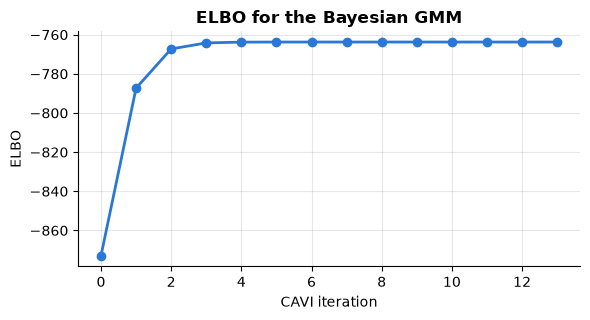

,true μ,Gibbs mean,VI mean,Gibbs sd,VI sd
0,-4.0,-3.950,-3.916,0.113,0.100
1,0.0,0.176,0.171,0.097,0.085
2,5.0,5.004,4.938,0.139,0.128


In [17]:
def cavi_gmm(x, K=3, sigma2=100.0, n_iter=100, seed=0, tol=1e-8):
    r = np.random.default_rng(seed)
    m = r.choice(x, K, replace=False).astype(float); s2 = np.ones(K)
    elbo_hist = []
    for _ in range(n_iter):
        logphi = m * x[:, None] - 0.5 * (s2 + m ** 2)                # update q(c_n)
        phi_ = np.exp(logphi - logsumexp(logphi, axis=1, keepdims=True))
        nk = phi_.sum(0)                                             # update q(mu_k)
        s2 = 1 / (1 / sigma2 + nk)
        m = s2 * (phi_ * x[:, None]).sum(0)
        # ELBO = E[log p(mu)] + E[log p(c)] + E[log p(x|c,mu)] + H[q(c)] + H[q(mu)]
        e_pmu = (-0.5 * np.log(2 * np.pi * sigma2) - (s2 + m ** 2) / (2 * sigma2)).sum()
        e_pc = -len(x) * np.log(K)
        e_px = (phi_ * (-0.5 * np.log(2 * np.pi) - 0.5 * (x[:, None] ** 2 - 2 * x[:, None] * m + s2 + m ** 2))).sum()
        h_c = -(phi_ * np.log(phi_ + 1e-300)).sum()
        h_mu = (0.5 * np.log(2 * np.pi * np.e * s2)).sum()
        elbo_hist.append(e_pmu + e_pc + e_px + h_c + h_mu)
        if len(elbo_hist) > 1 and elbo_hist[-1] - elbo_hist[-2] < tol:
            break
    o = np.argsort(m)
    return m[o], np.sqrt(s2[o]), np.array(elbo_hist)

t0 = time.time()
m_vi, s_vi, elbo_g = cavi_gmm(xb)
assert np.all(np.diff(elbo_g) >= -1e-8)
print(f"CAVI converged in {len(elbo_g)} iterations ({time.time() - t0:.3f}s); ELBO monotone")
cmp = pd.DataFrame({"true μ": true_mu_b, "Gibbs mean": tr_mu[burn:].mean(0), "VI mean": m_vi,
                    "Gibbs sd": tr_mu[burn:].std(0), "VI sd": s_vi})
fig, ax = plt.subplots(figsize=(6, 3.3))
ax.plot(elbo_g, marker="o"); ax.set_xlabel("CAVI iteration"); ax.set_ylabel("ELBO"); ax.set_title("ELBO for the Bayesian GMM")
plt.tight_layout(); plt.show()
cmp.round(3)

**What just happened?** CAVI reached essentially the same component means as Gibbs, in a few hundredths of a second instead of several seconds, and its uncertainty `sₖ` is in the same ballpark. (The two models differ slightly: our VI model fixes equal mixing weights, while the Gibbs model learned them; the means are well identified either way.) This speed-for-accuracy trade is the reason VI is used for large models.

**Complexity.** One CAVI iteration for the GMM is **O(N·K)**, the same as one EM iteration or one Gibbs sweep; but CAVI typically needs tens of iterations, while MCMC needs thousands of sweeps.

> ⚠️ **Common mistake:** expecting VI's credible intervals to be calibrated. Mean-field VI is usually **over-confident** (Section 8.1), and KL(q‖p) is **mode-seeking**: on a multimodal posterior, q locks onto one mode.

## 9. Stochastic VI and the reparameterisation trick

> 💬 **In plain English:** climb the ELBO with noisy gradients from small batches, using a trick that makes those gradients far less noisy.

**Intuition.** CAVI needs closed-form updates and touches all the data every step. For models like neural networks we instead maximise the ELBO by **stochastic gradient ascent**: estimate the gradient from a random **minibatch** of data (scaled by N/B) and a few random **samples** from q. This is **stochastic VI** (Hoffman et al., 2013) or, more generally, black-box VI.

The difficulty: we need `∇_φ E_{q_φ(z)}[f(z)]`, and the distribution itself depends on φ. Two estimators:

| Estimator | Formula | Needs | Variance |
|---|---|---|---|
| **Score function** (REINFORCE) | `E[f(z) ∇_φ log q_φ(z)]` | only log q's gradient; f can be non-differentiable | high |
| **Reparameterisation** (pathwise) | write `z = μ + σ·ε`, ε ~ N(0,1), then `E_ε[∇_φ f(μ + σε)]` | f differentiable in z, q reparameterisable | usually much lower |

The reparameterisation trick is what makes **VAEs** trainable ([`05_Deep_Learning/06_generative_models`](../../05_Deep_Learning/06_generative_models.ipynb)): the encoder outputs (μ, σ), we sample ε, and gradients flow through `z = μ + σε`.

First a toy where we know the answer: `∇_μ E_{z~N(μ,1)}[z²] = 2μ`.

In [18]:
mu_, sig_, S = 1.0, 1.0, 100000
eps = rng.normal(size=S); z = mu_ + sig_ * eps
g_score = (z ** 2) * (z - mu_) / sig_ ** 2          # f(z) * d/dmu log N(z | mu, sig^2)
g_reparam = 2 * z                                   # d/dmu f(mu + sig*eps) = f'(z)
print(pd.DataFrame({"mean (true = 2.0)": [g_score.mean(), g_reparam.mean()],
                    "variance per sample": [g_score.var(), g_reparam.var()]},
                   index=["score-function", "reparameterisation"]).round(3))

                    mean (true = 2.0)  variance per sample
score-function                  1.998               30.692
reparameterisation              1.996                4.018


SVI: 1200 steps in 1.7s


ESS of the MH chain per weight: [1885, 1616, 1313]
      true w  MCMC mean  VI mean  MCMC sd  VI sd
bias    -0.5     -0.481   -0.480    0.112  0.109
w1       1.5      1.363    1.348    0.144  0.135
w2      -1.0     -0.758   -0.776    0.126  0.115


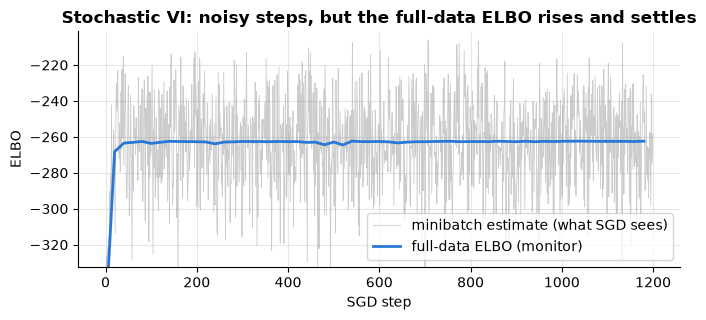

In [19]:
# Bayesian logistic regression: stochastic VI in torch vs a long random-walk Metropolis chain
Nl, Dl = 500, 3
Xl = np.c_[np.ones(Nl), rng.normal(size=(Nl, 2))]
w_true = np.array([-0.5, 1.5, -1.0])
yl = (rng.random(Nl) < 1 / (1 + np.exp(-Xl @ w_true))).astype(float)
Xt, yt = torch.tensor(Xl, dtype=torch.float32), torch.tensor(yl, dtype=torch.float32)

q_mu = torch.zeros(Dl, requires_grad=True)
q_logsd = torch.full((Dl,), -1.0, requires_grad=True)       # optimise log sd so sd stays positive
n_steps, B_, n_samples = 1200, 100, 8
opt = torch.optim.Adam([q_mu, q_logsd], lr=0.05)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, n_steps, eta_min=0.001)   # decaying step size (Robbins-Monro)
elbo_trace, full_elbo = [], []
t0 = time.time()
for step in range(n_steps):
    idx = torch.randint(0, Nl, (B_,))                       # random minibatch
    sd = q_logsd.exp()
    w = q_mu + sd * torch.randn(n_samples, Dl)              # reparameterised samples, shape (S, D)
    logits = Xt[idx] @ w.T                                   # (B, S)
    loglik = -torch.nn.functional.binary_cross_entropy_with_logits(
        logits, yt[idx, None].expand(-1, n_samples), reduction="none").sum(0).mean() * (Nl / B_)
    kl_ = 0.5 * (sd ** 2 + q_mu ** 2 - 1 - 2 * q_logsd).sum()   # KL(N(mu, sd^2) || N(0, 1)), closed form
    loss = -(loglik - kl_)                                   # maximise ELBO = minimise -ELBO
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    elbo_trace.append(-loss.item())
    if step % 20 == 0:                                       # monitor: full-data ELBO with many samples
        with torch.no_grad():
            wf = q_mu + q_logsd.exp() * torch.randn(256, Dl)
            llf = -torch.nn.functional.binary_cross_entropy_with_logits(
                Xt @ wf.T, yt[:, None].expand(-1, 256), reduction="none").sum(0).mean()
            klf = 0.5 * (q_logsd.exp() ** 2 + q_mu ** 2 - 1 - 2 * q_logsd).sum()
            full_elbo.append((step, (llf - klf).item()))
print(f"SVI: {n_steps} steps in {time.time() - t0:.1f}s")

def log_post(w):
    s = Xl @ w
    return (yl * s - np.logaddexp(0, s)).sum() - 0.5 * (w ** 2).sum()    # Bernoulli likelihood + N(0,1) prior
r_ = np.random.default_rng(5); w = np.zeros(Dl); lp = log_post(w); samples = []
for t in range(30000):
    prop = w + 0.12 * r_.normal(size=Dl)
    lpp = log_post(prop)
    if np.log(r_.random()) < lpp - lp:
        w, lp = prop, lpp
    samples.append(w.copy())
samples = np.array(samples[5000:])
print("ESS of the MH chain per weight:", [int(ess(samples[:, j])) for j in range(Dl)])
print(pd.DataFrame({"true w": w_true, "MCMC mean": samples.mean(0), "VI mean": q_mu.detach().numpy(),
                    "MCMC sd": samples.std(0), "VI sd": q_logsd.exp().detach().numpy()},
                   index=["bias", "w1", "w2"]).round(3))
fig, ax = plt.subplots(figsize=(7, 3.3))
ax.plot(elbo_trace, lw=0.6, alpha=0.4, color="grey", label="minibatch estimate (what SGD sees)")
ax.plot(*zip(*full_elbo), color=PALETTE[0], label="full-data ELBO (monitor)")
ax.set_xlabel("SGD step"); ax.set_ylabel("ELBO"); ax.set_ylim(np.percentile(elbo_trace, 1) - 5, max(elbo_trace) + 5)
ax.set_title("Stochastic VI: noisy steps, but the full-data ELBO rises and settles"); ax.legend(); plt.tight_layout(); plt.show()

**What just happened?** In the toy, both estimators are **unbiased** (means near 2.0), but the score-function estimator's variance is about 7–8 times larger than the reparameterisation estimator's (exactly 4 for the latter, since `Var[2z] = 4σ²`). That variance gap grows quickly with dimension, which is why VAEs use the reparameterisation trick.

For Bayesian logistic regression, stochastic VI with minibatches of 100, 8 Monte Carlo samples per step and a decaying learning rate (needed: with a constant step size the noisy gradients keep the answer jittering) recovers posterior means very close to a long Metropolis chain, and standard deviations that are close (mean-field Gaussians usually come out a little narrower, because they ignore the correlations between weights).

> 🎓 **Exam / interview tip:** the VAE loss is the negative ELBO: a reconstruction term `E_q[log p(x|z)]` plus `KL(q(z|x) ‖ p(z))`. The encoder is **amortised** VI: instead of one q per data point, a network maps x to q's parameters.

## 10. EM vs VI vs MCMC: when to use which

> 💬 **In plain English:** pick the tool by what you need: a quick fit, a fast approximate answer, or an accurate but slower one.

| | **EM** | **Variational inference** | **MCMC (Gibbs, MH, HMC)** |
|---|---|---|---|
| Output | a point estimate θ̂ (MLE or MAP) and the posterior over latents given θ̂ | an approximate posterior q over all unknowns | samples from the exact posterior (asymptotically) |
| Bias | none in the estimator definition, but a local optimum | **biased**: limited by the family of q (often over-confident) | asymptotically **unbiased**; finite-chain error shrinks like 1/√ESS |
| Cost per iteration | one E-step + one M-step (e.g. O(NKD²) for a GMM) | similar to EM (CAVI), or a minibatch gradient (SVI) | one sweep, but thousands are needed |
| Convergence check | log-likelihood stops rising | ELBO stops rising | ESS, R̂, trace plots (never certain) |
| Scales to huge data? | yes (online/stochastic EM) | **yes** (SVI with minibatches, amortisation) | hard (SG-MCMC exists but is delicate) |
| Uncertainty over parameters? | no | yes, approximate | yes, accurate |
| Typical use | GMMs, HMMs, missing data, mixture-of-experts, k-means-like problems | VAEs, LDA at scale, Bayesian NNs, large hierarchical models | small/medium Bayesian models where calibrated uncertainty matters (Stan, PyMC), scientific inference |

**Rules of thumb:** need only a good fit of a latent-variable model → **EM**. Need parameter uncertainty and the model is small or you need gold-standard answers → **MCMC** (with HMC/NUTS for continuous parameters). Need uncertainty at scale, or inference inside a neural network → **VI**. It is common to develop with MCMC on a subset and deploy with VI.

## 11. 🔗 How this connects to modern AI

- **VAEs and diffusion models** are trained by maximising an ELBO. A VAE uses amortised VI with the reparameterisation trick (Section 9; [`05_Deep_Learning/06_generative_models`](../../05_Deep_Learning/06_generative_models.ipynb)). The diffusion-model training loss is also a (re-weighted) variational bound on log p(x).
- **EM's ideas live on** in k-means (hard EM), self-training and pseudo-labelling in semi-supervised learning ([`03_semi_supervised`](../03_semi_supervised/01_semi_supervised_learning.ipynb)), mixture-of-experts gating, and in classic speech recognition (HMM-GMM acoustic models trained with Baum–Welch before deep learning).
- **Topic models**: LDA by collapsed Gibbs or VI ([`07_NLP/07_topic_modeling`](../../07_NLP/07_topic_modeling.ipynb)); modern embedding-based topic modelling still uses a clustering step that is often a GMM.
- **Uncertainty in deep learning**: Bayesian neural networks via VI ("Bayes by backprop"), MC dropout (interpretable as approximate VI), stochastic-gradient Langevin dynamics (SG-MCMC) and deep ensembles ([`14_conformal_prediction`](../14_conformal_prediction/01_conformal_prediction.ipynb), [`04_Forecasting/09_probabilistic_forecasting`](../../04_Forecasting/09_probabilistic_forecasting.ipynb)).
- **Probabilistic programming** (Stan, PyMC, NumPyro) automates exactly what you implemented here: HMC/NUTS samplers with ESS and R̂ diagnostics, and automatic-differentiation VI.
- **LLMs**: sampling text from a language model is ancestral sampling, not MCMC; but MCMC-style ideas appear in constrained decoding and in "sequential Monte Carlo steering" of LLM outputs, and the latent-variable view (rationale z, answer x) underlies some reasoning-training methods that maximise an ELBO over hidden chains of thought.

## 12. Recap

- Latent variables turn the likelihood into a **log of a sum**: no closed form, symmetric modes, local optima.
- **ELBO:** `log p(x) = 𝓛(q, θ) + KL(q ‖ p(z|x))`. **EM** = coordinate ascent: E-step sets q to the posterior, M-step maximises the expected complete-data log-likelihood; the likelihood never decreases.
- EM handles **mixtures**, **missing data** (use expected sufficient statistics, including the variance term) and **HMMs** (Baum–Welch with scaled forward–backward, O(T·K²)).
- **Gibbs sampling** redraws one variable at a time from its full conditional; collapsed Gibbs integrates out what it can (LDA). It mixes slowly when variables are strongly correlated.
- Diagnose MCMC with **trace plots, autocorrelation, ESS and split-R̂**; our ESS matched the AR(1) theory exactly.
- **Mean-field VI (CAVI)** maximises the ELBO over factorised q; it is fast, gives monotone ELBO curves, and is typically over-confident.
- **Stochastic VI** uses minibatches and Monte Carlo gradients; the **reparameterisation trick** gives low-variance gradients and powers VAEs.

## Practice problems

**1. (Easy, conceptual)** Why can the EM log-likelihood never decrease? Write the chain of (in)equalities.
<details><summary>Show solution</summary>

`log p(x|θ_new) ≥ 𝓛(q, θ_new) ≥ 𝓛(q, θ_old) = log p(x|θ_old)`, with q = p(z|x, θ_old). The first step is the ELBO bound (Jensen; the gap is a KL ≥ 0), the second is the M-step (θ_new maximises 𝓛(q, ·)), and the equality holds because the E-step makes the KL zero at θ_old. Note this proves monotonicity, not convergence to the global maximum.

</details>

**2. (Easy, conceptual)** Show that k-means is a limit of EM for a GMM.
<details><summary>Show solution</summary>

Take a GMM with equal weights and shared covariance σ²I. The responsibilities are `r_nk ∝ exp(−‖x_n − μ_k‖²/(2σ²))`. As σ → 0 the largest term dominates, so `r_nk → 1` for the nearest centroid and 0 otherwise ("hard" assignment). The M-step for μ_k becomes the mean of its assigned points. These are exactly the two steps of Lloyd's algorithm, and the EM objective becomes (up to constants and scaling) the k-means inertia Σ‖x_n − μ_{c(n)}‖².

</details>

**3. (Medium, coding)** Implement EM for a mixture of two **Poisson** distributions (counts such as "number of purchases"). Test it on 600 draws from Poisson(2) and 400 from Poisson(12).
<details><summary>Show solution</summary>

```python
def em_poisson_mixture(x, lam_init=(1.0, 10.0), n_iter=200):
    """EM for a 2-component Poisson mixture. Returns weights, rates, log-lik history."""
    import numpy as np
    from scipy.stats import poisson
    from scipy.special import logsumexp
    lam = np.array(lam_init, float); w = np.array([0.5, 0.5]); hist = []
    for _ in range(n_iter):
        logp = np.log(w) + poisson.logpmf(x[:, None], lam)       # E-step: (N, 2)
        ll = logsumexp(logp, axis=1)
        hist.append(ll.sum())
        r = np.exp(logp - ll[:, None])
        nk = r.sum(0)                                            # M-step: weighted averages
        w = nk / len(x)
        lam = (r * x[:, None]).sum(0) / nk
    return w, lam, np.array(hist)
```
The M-step for a Poisson rate is the responsibility-weighted mean of the counts. On the test data the rates come out within about 0.3 of 2 and 12, and the log-likelihood history is monotone.

</details>

**4. (Medium, conceptual)** A Gibbs chain's autocorrelation is well approximated by ρ_k = 0.9ᵏ. You ran 10 000 iterations. What is the ESS, and how many iterations would give an ESS of 1000?
<details><summary>Show solution</summary>

For AR(1) with φ = 0.9: ESS/N = (1 − φ)/(1 + φ) = 0.1/1.9 ≈ 0.0526, so ESS ≈ 526. To reach ESS = 1000 you need N ≈ 1000 × 19 = 19 000 iterations (the integrated autocorrelation time is τ = 1/0.0526 = 19).

</details>

**5. (Medium, coding)** Write a Gibbs sampler for `xₙ ~ N(μ, 1/τ)` with the **semi-conjugate** prior `μ ~ N(μ₀, s₀²)`, `τ ~ Gamma(a₀, b₀)` (independent priors). Derive both full conditionals first.
<details><summary>Show solution</summary>

Full conditionals: `μ | τ, x ~ N((μ₀/s₀² + τ n x̄)/P, 1/P)` with `P = 1/s₀² + nτ`; and `τ | μ, x ~ Gamma(a₀ + n/2, rate = b₀ + ½ Σ(xₙ − μ)²)`.
```python
def gibbs_normal_unknown_mean_precision(x, n_iter=5000, mu0=0.0, s0=10.0, a0=1.0, b0=1.0, seed=0):
    """Semi-conjugate model: mu ~ N(mu0, s0^2), tau ~ Gamma(a0, b0), x_n ~ N(mu, 1/tau)."""
    import numpy as np
    r = np.random.default_rng(seed); n, xbar = len(x), np.mean(x)
    mu, tau = xbar, 1.0; out = np.empty((n_iter, 2))
    for t in range(n_iter):
        prec = 1 / s0 ** 2 + n * tau                                    # mu | tau, x  is Normal
        mu = r.normal((mu0 / s0 ** 2 + tau * n * xbar) / prec, 1 / np.sqrt(prec))
        tau = r.gamma(a0 + n / 2, 1 / (b0 + 0.5 * np.sum((x - mu) ** 2)))   # tau | mu, x  is Gamma (scale = 1/rate)
        out[t] = mu, tau
    return out
```
Note NumPy's `gamma` takes a **scale** (1/rate). On 400 draws from N(3, 2²), the posterior mean of μ is within 0.05 of x̄ and the implied standard deviation within 0.1 of the sample's.

</details>

**6. (Medium, coding)** Implement split-R̂ and show it flags a run where one of four chains is stuck at a different location.
<details><summary>Show solution</summary>

```python
def split_rhat(chains):
    import numpy as np
    chains = np.asarray(chains); h = chains.shape[1] // 2
    c = np.vstack([chains[:, :h], chains[:, h:2 * h]])
    n = c.shape[1]
    W = c.var(axis=1, ddof=1).mean()
    B = n * c.mean(axis=1).var(ddof=1)
    return np.sqrt(((n - 1) / n * W + B / n) / W)
```
Four well-mixed chains give R̂ ≈ 1.00; shifting one chain by 3 standard deviations gives R̂ well above 1.1.

</details>

**7. (Hard, conceptual)** The true posterior of a parameter is an equal mixture of N(−3, 1) and N(3, 1). What does a single-Gaussian q fitted by (a) minimising KL(q‖p) (standard VI) and (b) minimising KL(p‖q) (as in expectation propagation) look like? Why?
<details><summary>Show solution</summary>

(a) **KL(q‖p) is mode-seeking ("zero-forcing")**: it is infinite wherever q has mass and p has almost none, so q avoids the gap between the modes and sits on **one** mode, roughly N(±3, 1). (b) **KL(p‖q) is mass-covering ("zero-avoiding")**: it is infinite wherever p has mass and q has none, so q must cover both modes; the optimum matches the moments of p, giving N(0, 1 + 9) = N(0, 10), which puts most mass in the gap where p is small. Neither is "right"; this is why VI can be over-confident and why multimodal posteriors need MCMC or mixture families.

</details>

**8. (Hard, coding project)** Replace the random-walk proposal in Section 9 with the **Metropolis-adjusted Langevin algorithm** (proposal mean `w + (ε²/2)∇log p(w)`, and remember the asymmetric proposal correction), and compare ESS per second with random-walk Metropolis.
<details><summary>Show solution</summary>

Sketch: `prop = w + 0.5*eps**2*grad(w) + eps*N(0,I)`; acceptance log-ratio = `lp(prop) − lp(w) + log q(w|prop) − log q(prop|w)`, where `log q(a|b) = −‖a − b − 0.5 eps² grad(b)‖²/(2 eps²)`. The gradient of the logistic log-posterior is `Xᵀ(y − σ(Xw)) − w`. Tune ε for roughly 57% acceptance (the optimal MALA rate). MALA typically gives several times the ESS per iteration of random-walk Metropolis in this problem; HMC improves further.

</details>

## Further reading
- C. M. Bishop, *Pattern Recognition and Machine Learning* (2006): ch. 9 (mixtures and EM), ch. 10 (variational inference), ch. 11 (sampling methods), ch. 13 (HMMs). Free PDF from Microsoft Research.
- K. P. Murphy, *Probabilistic Machine Learning: Advanced Topics* (2023): the inference chapters on VI and MCMC. Free at probml.github.io.
- A. P. Dempster, N. M. Laird, D. B. Rubin (1977), "Maximum likelihood from incomplete data via the EM algorithm"; L. R. Rabiner (1989), "A tutorial on hidden Markov models".
- D. M. Blei, A. Kucukelbir, J. D. McAuliffe (2017), "Variational Inference: A Review for Statisticians", *JASA*.
- T. L. Griffiths, M. Steyvers (2004), "Finding scientific topics", *PNAS* (collapsed Gibbs for LDA).
- A. Vehtari, A. Gelman, D. Simpson, B. Carpenter, P.-C. Bürkner (2021), "Rank-normalization, folding, and localization: an improved R̂", *Bayesian Analysis*.
- D. P. Kingma, M. Welling (2014), "Auto-Encoding Variational Bayes"; M. D. Hoffman et al. (2013), "Stochastic Variational Inference", *JMLR*.

## Next notebook
⬅️ Previous: [Markov networks and exact inference](01_markov_networks_and_exact_inference.ipynb) · ➡️ Next: [Clustering and manifold learning in depth](../02_unsupervised/05_clustering_and_manifold_learning_in_depth.ipynb)